# BIL545 · Proje 1 · Vizeye kadarki konular (2.–7. haftalar)
**Veri Madenciliğinde İleri Konular · 2026–2027 Güz** · **Vize Projesi**


## Grup bilgisi
| | Ad Soyad | Öğrenci no |
|---|---|---|
| Üye 1 | Nurseda Akgül | 244329048 |
| Üye 2 | Kübra Girit Kopuz | 244329057 |
| Üye 3 | Barış Refik Aykent | 244329058 |
| Üye 4 | Elif Öztürk | 244329059 |
| Üye 5 | Alicem Elverdi | 244329066 |

**Grup adı:** Grup04  
**GitHub deposu:** https://github.com/efulii/datamining  
**Seçilen konu:** 9.19 · İstanbul'da Airbnb ilanları  
**Grup tipi:** 5 kişi (temel kapsam + Ek paket 1 + Ek paket 2)  
**Veri kümesi ve sorumuz (tek cümle):** Inside Airbnb İstanbul (25.09.2026 kazıması ve fiyatı görünen bütün ilanlar dahil edilmiştir.). Bir ilanın yapısal, ev sahibi ve konum gibi özelliklerinden fiyat dilimi ( ucuz/orta/pahalı) ne kadar doğru tahmin edilebilir olduğunu belirlemek mümkün mü? Bu sonuçlar hangi özellikler ile belirlenebilir?


## Hazırlık

In [1]:
import sys, warnings, numpy as np, pandas as pd, sklearn, scipy, matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)
#Çapraz doğrulama bölmeleri, modeller, k-means random_state=SEED ile çalışır.
SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 50, "display.width", 200)
#Kütüphaneler ve sürüm bilgileri
print("Python      ", sys.version.split()[0]); print("numpy       ", np.__version__)
print("pandas      ", pd.__version__);          print("scikit-learn", sklearn.__version__)
print("scipy       ", scipy.__version__);       print("matplotlib  ", matplotlib.__version__)

Python       3.13.18
numpy        2.4.6
pandas       2.2.3
scikit-learn 1.6.1
scipy        1.16.3
matplotlib   3.10.0


### Veriyi yükleme
**Kaynak:** [Inside Airbnb · İstanbul](https://insideairbnb.com/get-the-data/) · `listings.csv.gz` (ayrıntılı ilan dosyası), kazıma tarihi 25 Eylül 2026  
**Lisans:** Creative Commons Attribution 4.0 (CC BY 4.0)  
**İndirme / yükleme adımı:** Veri doğrudan Inside Airbnb bağlantısından okunur. Inside Airbnb eski kazımaları zamanla kaldırabildiği için çalışma yapılan dosyanın yedeği grup üyeleri tarafından saklanmıştır. Bağlantının çalışmaması durumunda yedek dosya Colab'in Dosyalar paneline yüklenir ve kullanılabilir.

In [2]:
VERI_URL = "https://data.insideairbnb.com/turkey/marmara/istanbul/2026-09-25/data/listings.csv.gz"
df_ham = pd.read_csv(VERI_URL, low_memory=False)
print("Kaynak :", VERI_URL)
print("Boyut :", df_ham.shape)
assert df_ham["scrape_id"].nunique() == 1 and df_ham.shape == (27232, 90), "Beklenen kazıma değil!"

Kaynak : https://data.insideairbnb.com/turkey/marmara/istanbul/2026-09-25/data/listings.csv.gz
Boyut : (27232, 90)


# Bölüm 1 · Veri, ön işleme ve sızıntı *(ağırlık 30)*
**Makale:** Kaufmann vd. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM TKDD*, 6(4).

**Okuma notu:** Kaufmann vd. sızıntıyı tahmin anında bilinemeyecek hedef bilgisinin modele girmesi olarak tanımlar. Sızıntı ikiye ayrılır:

*   Öznitelik sızıntısı: Hedefi ya da hedeften sonra oluşan bilgiyi taşıyan sütunlar
*   Eğitim örneği sızıntısı: Test örnekleri hakkındaki bilginin eğitim bilgisine karışması

Sızıntıyı önlemenin temel ilkesi; öğren-tahmin et ayırımını kurmaktır. Her öznitelik ve her ön işleme adımı yalnız tahmin anında meşru olarak elde edilebilecek bilgi ve yalnızca eğitim verisinden kurulmalıdır. Makalede sızıntıyı bulabilmek için veri üretim sürecini ve veriyi anlamak, şüpheli derecede iyi öznitelikleri ve skorları sorgulamak önerilir. Sızıntıyı sonradan temizlemek yerine veri ön işleme aşamasında önlemek için yöntemler belirlemenin daha güvenli olduğu savunulur.
Bu çalışmada iki tür de sınanmıştır. Fiyattan türetilmiş sütunlar öznitelik sızıntısı, aynı ev sahibine ait verilerin eğitim ve test kümelerinde dağılması ise örnek sızıntısı olarak ele alınmıştır.

### 1.1 Veri künyesi
| Soru | Cevap |
|---|---|
| Kim, hangi amaçla topladı? | **Inside Airbnb**: Airbnb'den bağımsız olarak çalışan kâr amacı gütmeyen bir proje kapsamında çalışmaktadır. Kısa dönem kiralamanın kiralama yapılan mahalleler ve konutlar üzerindeki etkisinin anlaşılması amacıyla Airbnb'nin public ilan sayfaları kazıyarak elde edilen verilerden oluşur. Airbnb'nin resmi verisi değildir. |
| Hangi dönemi kapsıyor? | Tek bir kesit: 25 Eylül 2026 kazıması ile 28-29 Eylül 2026 tarihleri arası sayfalar okunarak elde edilmiştir. Yorumlar ise 2011-2026 yılları arasını kapsamaktadır. `source = previous scrape` olan ilanların bu kazımada güncel okunamadığı önceki kazımadan taşınmış olabileceği düşünülmektedir. Bu oran %39 olarak hesaplanmıştır. |
| Hedef gerçek olgu mu, vekil mi? | **Vekil.** Bu çalışmada bilmek istediğimiz; ilanın İstanbul Airbnb pazarındaki fiyat düzeyidir ve  `price` özniteliği bunu doğrudan ölçmemektedir. Veride bulunan fiyat kazıma sırasında belirli tarih aralığı için alınan fiyat teklifinin gece başı değeridir.  (`price` değeri `price_quote_price_per_night` ile birebir aynı). Fiyat değeri ev sahibi tarafından belirlenen; gerçekleşen kira, doluluk ya da evin piyasa değeri değil ev sahinin talep ettiği fiyattır.<br>Ev aynı kalsa bile fiyat değeri aşağıda belirtilen ölçüm koşullarına göre değişebilir: <br> **(1) Fiyat teklifin süresine bağlı olarak değişebilir:** İlanların %36,4'ünde en az konaklama 100 gece ve daha fazla gözükmektedir ve bu uzun süreli ilanların medyan gecelik fiyatı diğerlerinin yarısından daha azdır. (2.062 / 4.458 TL) Bu durum büyük olasılıkla uzun konaklama indiriminden kaynaklanmaktadır. <br> **(2) Dönemsel fiyat değişikliği**: İlanların teklifleri farklı dönemler için alınsaydı farklı fiyatlar çıkarılabilirdi. <br> **(3) Ev sahibinin fiyat stratejisi**: Yüksek fiyat talep edildiği halde kiralanamayan evler bulunabilir. Bu evler veride "pahalı" olarak görünür, fakat bu evin gerçek durumunu ifade etmeyebilir. Ev sahibinin yüksek fiyat stratejisi de olabilir. |
| Kimler eksik temsil ediliyor olabilir? | **Pasif ilanlar:** Fiyatı boş %9,8 ilan hedefi olmadığı için modelden çıkarılmıştır; çıkarılan satırların %97'si önceki kazılmadan taşınmış ve daha az aktif olanlardır. Çıkarılan ilenların son yorumlarının medyanı Haziran 2024'dür. Fiyatlı ilanların ise son yorumlarının medyanı Ağustos 2026'dır. <br>**İzinsiz kısa dönem kiralama ihtimali:** 7464 sayılı Kanun'la (1 Ocak 2024) 100 günden kısa turizm amaçlı kiralama izne bağlanmakla birlikte izinsiz kısa dönem kiralayanlar "en az 100 gece" yazarak görünmüş ve kısa dönem kiralama yapılmış olabilir. Veri gerçek davranışı değil ev sahibinin beyanını göstermektedir.<br>**Merkez dışı ilçeler:** İlanlar merkezde yoğun olarak bulunmaktadır. (Beyoğlu 7.447, Sultangazi 17); az ilanlı ilçelerde model daha az öğrenmektedir.<br>**Puanlar:** Yalnız yorum bırakan misafirler temsil edilmektedir. |
| Lisans | CC BY 4.0 (Inside Airbnb). Kaynak gösterilerek akademik kullanım ve yeniden paylaşım serbest. Veride kişisel veri olarak ev sahibi adı ve profil fotoğrafı bağlantısı var; modelde kullanılmıyor. |

In [3]:
# Künyedeki cevapları destekleyen sayılar
tarih = lambda c: pd.to_datetime(df_ham[c], errors="coerce")
print("Kazıma kimliği (scrape_id):", df_ham["scrape_id"].unique())
print("Kazıma günleri (last_scraped):", sorted(df_ham["last_scraped"].unique()))
print("İlk yorum tarihi aralığı :", tarih("first_review").min().date(), "→", tarih("first_review").max().date())
print("Son yorum tarihi aralığı :", tarih("last_review").min().date(), "→", tarih("last_review").max().date())
print("Ev sahipliği süresi (yıl):", df_ham["hosts_time_as_host_years"].describe()[["min", "50%", "max"]].to_dict())

fiyat_ham = df_ham["price"].str.replace(r"[$,]", "", regex=True).astype(float)
print(f"\nFiyatı boş ilan oranı: {fiyat_ham.isna().mean():.1%}")
print("Fiyat teklifi gece sayısı (checkout − checkin), en sık 5 değer:")
gece = (tarih("price_quote_checkout_date") - tarih("price_quote_checkin_date")).dt.days
print(gece.value_counts().head(5).to_string())
print("Teklif süresi en az / en çok (gece):", gece.min(), "/", gece.max(), f"· 100 geceyi aşan: {(gece > 100).sum()} ilan")
print("\nEn az konaklama ≥ 100 gece olan ilan oranı (bütün ilanlar içinde):", f"{(df_ham['minimum_nights'] >= 100).mean():.1%}")
print("Medyan gecelik fiyat (TL), en az konaklamaya göre:")
print(fiyat_ham.groupby(np.where(df_ham["minimum_nights"] >= 100, "≥100 gece", "<100 gece")).median().round(0).to_string())

print(f"\nÖnceki kazımadan taşınan ilan oranı (source = previous scrape): {(df_ham['source'] == 'previous scrape').mean():.1%}")
print(f"Fiyatı boş ilanlar · önceki kazımadan: {(df_ham.loc[fiyat_ham.isna(), 'source'] == 'previous scrape').mean():.0%}",
      f"· medyan son yorum: {tarih('last_review')[fiyat_ham.isna()].median().date()}",
      f"(fiyatlılarda {tarih('last_review')[fiyat_ham.notna()].median().date()})")
print("İlçe başına ilan · en çok:", df_ham["neighbourhood_cleansed"].value_counts().head(3).to_dict(),
      "· en az:", df_ham["neighbourhood_cleansed"].value_counts().tail(3).to_dict())

Kazıma kimliği (scrape_id): [20260925130056]
Kazıma günleri (last_scraped): ['2026-09-28', '2026-09-29']
İlk yorum tarihi aralığı : 2011-05-17 → 2026-09-28
Son yorum tarihi aralığı : 2012-01-07 → 2026-09-28
Ev sahipliği süresi (yıl): {'min': 0.0, '50%': 3.0, 'max': 15.0}

Fiyatı boş ilan oranı: 9.8%
Fiyat teklifi gece sayısı (checkout − checkin), en sık 5 değer:
1.0      8409
100.0    8215
2.0      4644
3.0      2192
5.0       453
Teklif süresi en az / en çok (gece): 1.0 / 365.0 · 100 geceyi aşan: 548 ilan

En az konaklama ≥ 100 gece olan ilan oranı (bütün ilanlar içinde): 36.4%
Medyan gecelik fiyat (TL), en az konaklamaya göre:
<100 gece    4458.0
≥100 gece    2062.0

Önceki kazımadan taşınan ilan oranı (source = previous scrape): 39.2%
Fiyatı boş ilanlar · önceki kazımadan: 97% · medyan son yorum: 2024-06-04 (fiyatlılarda 2026-08-13)
İlçe başına ilan · en çok: {'Beyoglu': 7447, 'Fatih': 4135, 'Sisli': 3722} · en az: {'Catalca': 27, 'Sultanbeyli': 18, 'Sultangazi': 17}


**Yorum**

Hedefimiz bir vekil olduğu için modelin öğreneceği şey "evin değeri" değil, *ilan sahibinin bu kazıma anında belirli bir konaklama için istediği gecelik fiyat*tır.En büyük ölçüm sorunu en az 100 gece kuralı: İlanların %36,4'ünde en az konaklama 100 gece ya da daha fazladır; bu ilanlarda fiyat teklifi de 100 gece ya da daha uzun bir konaklama için verilmiştir. Bu ilanların medyan gecelik fiyatı 2.062 TL olarak hesaplanmıştır. 100 geceden az olanlarda ise medyan fiyat teklifi 4.458 TL olarak hesaplanmıştır. Bu fark büyük olasılıkla uzun konaklama indirimi; yani aynı ev, en az konaklaması değişince başka dilime düşebilir. Bu etki modele `log_min_gece` ile verilmiştir. Bir yandan da bu ilanların bir kısmının gerçekten kısa dönem kiralanıp kiralanmadığı veriyle doğrulanamamaktadır.

**Neyi söyleyemeyiz:** Sonuçlar başka bir tarih aralığına (Türk lirasında yaşanacak değer kaybı sınırları anlamsızlaştırır) ya da başka bir şehre taşınamaz. Veri tek bir kazımadan geldiği için tüm yılı kapsayan bir analiz olduğu söylenemez. Aynı zamanda fiyatı olmayan %9,8'lik daha pasif ilanlar hakkında bir analiz yapılamamaktadır.

### 1.2 Keşifsel analiz
Boyut; saklama ve ölçek tipleri; hedef dağılımı; yinelenen satırlar; künye tablosu (tip, eksik oranı, farklı değer sayısı, sıfır oranı); şüpheli öznitelik listesi.

Satır × sütun: 27,232 × 90  ·  bellek: 142 MB
Farklı ev sahibi: 9,967  ·  farklı ilçe: 39

Terciller: [2731.0, 5100.0] → yuvarlanmış eşikler: [2750, 5100]
count      24553.0
mean        6022.0
std        38240.0
min           79.0
1%           417.0
50%         3710.0
99%        38318.0
max      4989148.0

Hedef dağılımı (fiyatı olan ilanlar):
              count  proportion
fiyat_dilimi                   
ucuz           8311       0.338
orta           8061       0.328
pahalı         8181       0.333


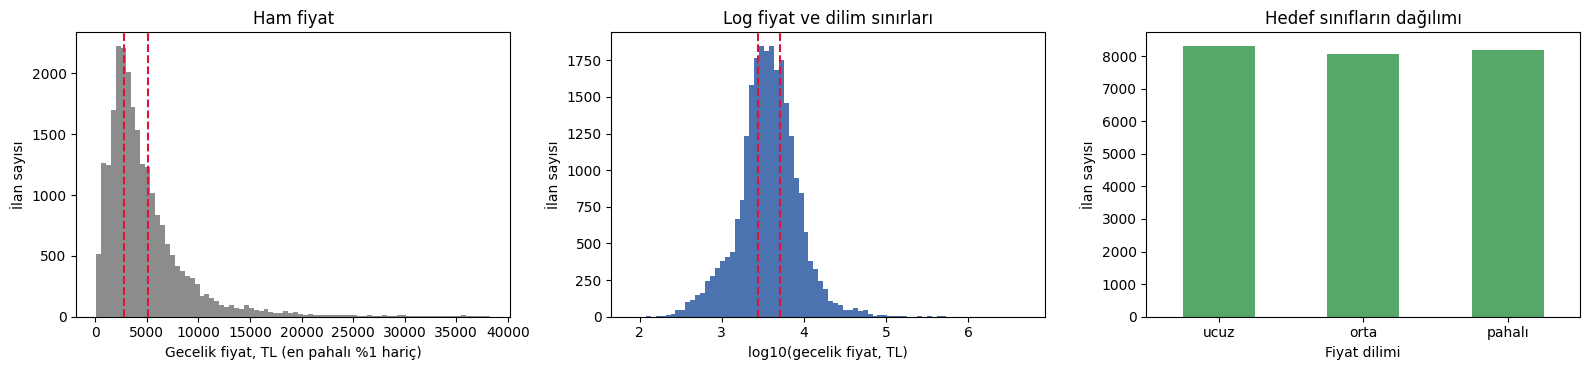

Grafik: ham fiyat sağa çok çarpık (çarpıklık 100.3; en pahalı %1 dışarıda bırakılsa bile uzun bir sağ kuyruk var), log ölçekte neredeyse simetrik (çarpıklık 0.17). Kesikli çizgiler 2,750 ve 5,100 TL sınırları; sınıflar yaklaşık dengeli.


In [6]:
df = df_ham.copy() # ham veri korunur; bütün düzeltmeler bu kopya üzerinde yapılır
df["fiyat"] = df["price"].str.replace(r"[$,]", "", regex=True).astype(float)   # "$4,736.32" → 4736.32 (birim TL)

# Boyut
print(f"Satır × sütun: {df_ham.shape[0]:,} × {df_ham.shape[1]}  ·  bellek: {df_ham.memory_usage(deep=True).sum()/1e6:.0f} MB")
print(f"Farklı ev sahibi: {df['host_id'].nunique():,}  ·  farklı ilçe: {df['neighbourhood_cleansed'].nunique()}")

# Hedef: fiyat dilimi (3 sınıf) — eşikler veriden: terciller, en yakın 50 TL'ye yuvarlanır
# Hedef tanımı: eşikler bütün veriden BİR KEZ hesaplanır (hedef bütün katlarda aynı olmalı, yoksa skorlar karşılaştırılamaz);
# katlardan bağımsızlığı 1.3'teki kontrol hücresinde ölçüldü: eşikler yalnız eğitim katından hesaplansa da hiçbir etiket değişmiyor.
SINIFLAR = ["ucuz", "orta", "pahalı"]
YUVARLAMA = 50
terciller = df["fiyat"].quantile([1/3, 2/3]) # fiyatları üç eşit parçaya bölen iki değer (fiyatı boş ilanlar hesaba girmez)
ESIKLER = (terciller / YUVARLAMA).round().mul(YUVARLAMA).astype(int).tolist() # en yakın 50 TL'ye yuvarlama: 2731 → 2750
print("\nTerciller:", terciller.round(0).tolist(), "→ yuvarlanmış eşikler:", ESIKLER)
print(df["fiyat"].describe(percentiles=[.01, .5, .99]).round(0).to_string())
df["fiyat_dilimi"] = pd.cut(df["fiyat"], [-np.inf, *ESIKLER, np.inf], labels=SINIFLAR, right=False)
print("\nHedef dağılımı (fiyatı olan ilanlar):")
print(pd.concat([df["fiyat_dilimi"].value_counts().reindex(SINIFLAR),
                 df["fiyat_dilimi"].value_counts(normalize=True).reindex(SINIFLAR).round(3)], axis=1).to_string())

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].hist(df["fiyat"][df["fiyat"] <= df["fiyat"].quantile(0.99)], bins=80, color="#8C8C8C")   # en pahalı %1 dışarıda: yoksa her şey tek çubuğa düşer
for e in ESIKLER: ax[0].axvline(e, color="crimson", ls="--")
ax[0].set(xlabel="Gecelik fiyat, TL (en pahalı %1 hariç)", ylabel="İlan sayısı", title="Ham fiyat")
ax[1].hist(np.log10(df["fiyat"].dropna()), bins=80, color="#4C72B0")
for e in ESIKLER: ax[1].axvline(np.log10(e), color="crimson", ls="--")
ax[1].set(xlabel="log10(gecelik fiyat, TL)", ylabel="İlan sayısı", title="Log fiyat ve dilim sınırları")
df["fiyat_dilimi"].value_counts().reindex(SINIFLAR).plot.bar(ax=ax[2], color="#55A868", rot=0)
ax[2].set(xlabel="Fiyat dilimi", ylabel="İlan sayısı", title="Hedef sınıfların dağılımı")
plt.tight_layout(); plt.show()
print(f"Grafik: ham fiyat sağa çok çarpık (çarpıklık {df['fiyat'].skew():.1f}; en pahalı %1 dışarıda bırakılsa bile uzun bir sağ kuyruk var), "
      f"log ölçekte neredeyse simetrik (çarpıklık {np.log10(df['fiyat']).skew():.2f}). "
      f"Kesikli çizgiler {ESIKLER[0]:,} ve {ESIKLER[1]:,} TL sınırları; sınıflar yaklaşık dengeli.")

**Yorum** · Hedefin tanımı ve dağılımı

**Ne bulduk:** Veride 27.232 ilan ve 90 sütun görülmüştür. İlanların 9.967 ev sahibine ait ve 39 ilçeye dağıldığı izlenmiştir. Fiyat alanı dolu olan 24.553 ilan hedef tanımına girmektedir. Ham gecelik fiyat sağa çarpıktır: medyan 3.710 TL, ortalama 6.022 TL, en yüksek değer 4,99 milyon TL'dir. Ortalamanın medyandan bu kadar yüksek olması, az sayıda çok pahalı ilanın ortalamayı yukarı çektiğini göstermektedir. Logaritma alındığında dağılım neredeyse simetrik hâle gelmektedir. Fiyat tercillerine göre üç dilime bölünmüş, sınırlar en yakın 50 TL'ye yuvarlanarak 2.750 ve 5.100 TL olarak belirlenmiştir. Sınıfların dengeli olarak dağıldığı görülmüştür: Ucuz %33,8, orta %32,8, pahalı %33,3.

**Ne anlama geliyor:** Fiyatın çarpık olması sonucunda iki karar alınmıştır.

1.   Hedef değer aralığına göre değil sıraya göre (terciller) bölünmüştür; böylece uç değerler sınırları kaydıramaz (gerekçesi aşağıdaki karşılaştırmada).
2.   Fiyatla ilişki ölçülürken Pearson yerine Spearman korelasyonu kullanılmıştır (otomatik sızıntı taraması). Sınıfların dengeli olması, modelin tek bir sınıfı tahmin ederek yüksek doğruluk elde edememesi anlamına gelir; yine de her sınıfa eşit ağırlık vermek için ana ölçüt olarak makro F1 kullanılmıştır (1.6).

**Neyi söyleyemeyiz:** Dağılım özetine göre ilanların en ucuz %1'i 417 TL'nin, en pahalı %1'i 38.318 TL'nin ötesindedir; en düşük fiyat 79 TL, en yüksek 4,99 milyon TL'dir. Bu uç değerlerin gerçek fiyat mı yoksa hatalı giriş mi olduğunu veriden ayırt edemeyiz. Tercil bölmesi sıraya baktığı için bu ilanlar dilim sınırlarını değiştirmez, yalnızca "ucuz" ya da "pahalı" sınıfına düşer; bu nedenle veride bırakılmıştır.

#### Hedef için bölme alternatiflerinin karşılaştırılması
Eşit frekanslı (tercil) bölmenin gerekçesinin diğer bölme yöntemleri oluşturularak netleştirilmiştir. Aynı fiyat aralığı ham fiyat eşit genişlik, log fiyat eşit genişlik, K-means, eşit frakans yöntemleri ile bölünerek sonuçlar karşılaştırılmıştır.

,sınır 1 (TL),sınır 2 (TL),ucuz,orta,pahalı,en küçük sınıf %,dengesizlik (en büyük / en küçük)
yöntem,,,,,,,
Eşit genişlik (ham fiyat),1663102,3326125,24550,2,1,0.0,24550.0
Eşit genişlik (log fiyat),3134,125045,10056,14465,32,0.1,452.0
"Kümeleme (k-ortalamalar, log fiyat)",1829,5698,4016,13708,6829,16.4,3.4
Eşit frekans (terciller),2731,5100,8168,8137,8248,33.1,1.0
Seçilen: yuvarlanmış terciller,2750,5100,8311,8061,8181,32.8,1.0


Kontrol: hedefte kullanılan eşikler ile 'Seçilen' satırı aynı ✓ [2750.0, 5100.0]


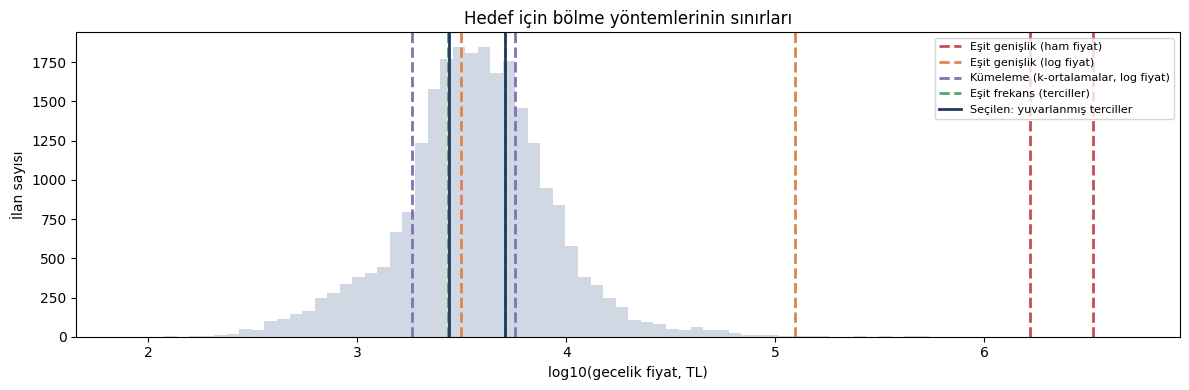

Grafik: gri çubuklar fiyat dağılımı (log ölçek); her renk bir yöntemin iki sınırı. Eşit genişlik sınırları dağılımın sağ kuyruğuna düşüyor, terciller yoğun bölgeyi üçe ayırıyor.

Alternatif büyüklükler (aynı tercil yöntemiyle):
  Kişi başı fiyat          → sınırlar: [959.0, 1533.0] TL/kişi
  İlçe medyanına göre oran → sınırlar: [0.74, 1.33] (1,0 = ilçe medyanı)


In [8]:
# Hedef için bölme alternatiflerinin karşılaştırılması
from sklearn.cluster import KMeans

f = df["fiyat"].dropna()
log_f = np.log10(f)

def sinirlari_bul(yontem):
    if yontem == "Eşit genişlik (ham fiyat)":
        return np.linspace(f.min(), f.max(), 4)[1:-1]
    if yontem == "Eşit genişlik (log fiyat)":
        return 10 ** np.linspace(log_f.min(), log_f.max(), 4)[1:-1]
    if yontem == "Kümeleme (k-ortalamalar, log fiyat)":
        km = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(log_f.to_frame())
        m = np.sort(km.cluster_centers_.ravel())
        return 10 ** ((m[:-1] + m[1:]) / 2)               # iki küme merkezinin ortası = sınır
    if yontem == "Eşit frekans (terciller)":
        return f.quantile([1/3, 2/3]).to_numpy()
    if yontem == "Seçilen: yuvarlanmış terciller":
        return (f.quantile([1/3, 2/3]) / YUVARLAMA).round().to_numpy() * YUVARLAMA

YONTEMLER = ["Eşit genişlik (ham fiyat)", "Eşit genişlik (log fiyat)", "Kümeleme (k-ortalamalar, log fiyat)",
             "Eşit frekans (terciller)", "Seçilen: yuvarlanmış terciller"]
satirlar = []
for yontem in YONTEMLER:
    s = sinirlari_bul(yontem)
    assert s is not None and len(s) == 2, f"'{yontem}' iki sınır döndürmedi: {s}"
    sayilar = pd.cut(f, [-np.inf, *s, np.inf], right=False).value_counts(sort=False).to_numpy()
    satirlar.append({"yöntem": yontem,
                     "sınır 1 (TL)": round(s[0]), "sınır 2 (TL)": round(s[1]),
                     "ucuz": sayilar[0], "orta": sayilar[1], "pahalı": sayilar[2],
                     "en küçük sınıf %": round(100 * sayilar.min() / sayilar.sum(), 1),
                     "dengesizlik (en büyük / en küçük)": round(sayilar.max() / sayilar.min(), 1)})
bolme_tablosu = pd.DataFrame(satirlar).set_index("yöntem")
display(bolme_tablosu)

# Tutarlılık kontrolü: hedefi oluşturan ESIKLER ile bu tablodaki "Seçilen" satırı aynı mı?
secilen = bolme_tablosu.loc["Seçilen: yuvarlanmış terciller", ["sınır 1 (TL)", "sınır 2 (TL)"]].tolist()
assert secilen == list(ESIKLER), f"4a'daki ESIKLER {ESIKLER} ile karşılaştırmadaki sınırlar {secilen} farklı!"
print("Kontrol: hedefte kullanılan eşikler ile 'Seçilen' satırı aynı ✓", secilen)

# Grafik: her yöntemin sınırları aynı log-fiyat dağılımı üzerinde
fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(log_f, bins=80, color="#cfd8e3")
renkler = ["#C44E52", "#DD8452", "#8172B3", "#55A868", "#1f3b5c"]
for (yontem, r), renk in zip(bolme_tablosu.iterrows(), renkler):
    for j, sinir in enumerate([r["sınır 1 (TL)"], r["sınır 2 (TL)"]]):
        ax.axvline(np.log10(sinir), color=renk, ls="--" if "Seçilen" not in yontem else "-", lw=2,
                   label=yontem if j == 0 else None)
ax.set(xlabel="log10(gecelik fiyat, TL)", ylabel="İlan sayısı", title="Hedef için bölme yöntemlerinin sınırları")
ax.legend(fontsize=8, loc="upper right"); plt.tight_layout(); plt.show()
print("Grafik: gri çubuklar fiyat dağılımı (log ölçek); her renk bir yöntemin iki sınırı. "
      "Eşit genişlik sınırları dağılımın sağ kuyruğuna düşüyor, terciller yoğun bölgeyi üçe ayırıyor.")

# Ne böldüğümüz de bir seçim: kapasite ve konum etkisini ayıran iki alternatif büyüklük
kisi_basi = df["fiyat"] / df["accommodates"]
ilceye_gore = df["fiyat"] / df.groupby("neighbourhood_cleansed")["fiyat"].transform("median")
print("\nAlternatif büyüklükler (aynı tercil yöntemiyle):")
print(f"  Kişi başı fiyat          → sınırlar: {kisi_basi.quantile([1/3, 2/3]).round().tolist()} TL/kişi")
print(f"  İlçe medyanına göre oran → sınırlar: {ilceye_gore.quantile([1/3, 2/3]).round(2).tolist()} (1,0 = ilçe medyanı)")

**Yorum** · Hedef için bölme yönteminin seçimi

**Ne bulduk:** Aynı gecelik fiyatı dört yöntemle üç dilime ayırdık:

1. **Eşit genişlik (ham fiyat):** Bu veride kullanılamaz. İlk sınır 1,66 milyon TL'ye düştüğü için ilanların neredeyse tamamı (24.550 / 24.553) "ucuz" sınıfına giriyor.
2. **Eşit genişlik (log fiyat):** Log ölçekte bile en yüksek fiyatlar (en fazla ~5 milyon TL) üst sınırı 125.045 TL'ye itiyor ve "pahalı" sınıfında yalnız 32 ilan kalıyor.
3. **k-ortalamalar (log fiyat):** Daha doğal sınırlar buluyor (1.829 / 5.698 TL), ama ilanların %56'sını orta sınıfa topluyor.
4. **Eşit frekans (terciller):** Sınırlar 2.731 / 5.100 TL; üç dengeli sınıf veriyor.

Sınırları en yakın 50 TL'ye yuvarlamak (2.750 / 5.100 TL) sınıf paylarını en fazla 0,6 puan değiştiriyor.

**Ne anlama geliyor:** Fiyat dağılımı aşırı sağa çarpık olduğu için, değer aralığını eşit bölen yöntemler sınırları birkaç uç ilanın belirlediği boş bölgelere koyuyor. Eşit frekanslı bölme ise değerlere değil sıralara baktığı için uç değerlerden etkilenmiyor: 5 milyon TL'lik bir ilan da yalnızca "pahalı" sınıfına girer. Dengeli sınıflar modelin "hep en kalabalık sınıfı söyle" kolaylığına kaçmasını engeller. Bu nedenle hedef için yuvarlanmış tercilleri seçtik. Model için kullanılan eşikler (`ESIKLER_MODEL`, 1.3) seçilen kapsamdan aynı yöntemle hesaplandığı için kapsam değişirse (ör. yalnız kısa dönem ilanlar) yeni kitleye göre kendiliğinden güncellenir.

Bölünen büyüklük de bir seçimdir. Kişi başı fiyat (sınırlar 959 / 1.533 TL/kişi) kapasiteyi, ilçe medyanına göre göreli fiyat (0,74 / 1,33) ise konumu hedeften arındırır. Bunlar "evin büyüklüğü ve yeri dışında fiyatı ne belirliyor?" sorusuna yönelir ve Proje 2'de ilçe düzeyindeki fiyat farklarını incelemek için bir genişletme yönü oluşturur.

**Neyi söyleyemeyiz:** Hangi bölmenin "doğru" olduğu veriden değil, sorulan sorudan çıkar. Tercillerin piyasada "ucuz" ya da "pahalı" denen bir eşiğe karşılık geldiğini söyleyemeyiz. Sınırlar keskin olduğu için 2.749 TL ile 2.751 TL'lik iki benzer ilan farklı sınıflara düşüyor; orta dilimin iki komşusuyla sınır paylaşması modelin bu sınıfta zorlanmasına yol açabilir. Eşikler bu kazımaya (Eylül 2026, TL) özgüdür.

Bölme yöntemini model başarımına bakarak değil, sınıf dağılımına bakarak seçtik: hedef tanımını model skoruna göre ayarlamak değerlendirmeyi iyimser yapardı.

#### Yinelenenler, künye tablosu ve otomatik sızıntı taraması

In [9]:
# Yinelenen satırlar
kimlikler = ["id", "listing_url", "picture_url", "price_quote_raw"]
print("Tam yinelenen satır (kimlik/URL sütunları hariç):", df_ham.drop(columns=kimlikler).duplicated().sum())
neredeyse = df.duplicated(["host_id", "name", "room_type", "accommodates", "neighbourhood_cleansed"], keep=False)
print("Aynı ev sahibi + aynı ad + aynı oda tipi/kapasite/ilçe olan ilan:", int(neredeyse.sum()))
ilan_sayisi = df.groupby("host_id")["id"].transform("size")
print(f"İlanların {(ilan_sayisi >= 10).mean():.1%}'i 10+ ilanı olan ev sahiplerine ait; en büyük ev sahibinin {ilan_sayisi.max()} ilanı var.")

# Künye tablosu: her sütun için tip, eksik oranı, farklı değer sayısı, sıfır oranı
kunye = pd.DataFrame({
    "saklama_tipi": df_ham.dtypes.astype(str),
    "eksik_orani": df_ham.isna().mean().round(3),
    "farkli_deger": df_ham.nunique(),
    "sifir_orani": df_ham.apply(lambda s: (s == 0).mean() if pd.api.types.is_numeric_dtype(s) else np.nan).round(3),
})
with pd.option_context("display.max_rows", 100):
    display(kunye)

Tam yinelenen satır (kimlik/URL sütunları hariç): 22
Aynı ev sahibi + aynı ad + aynı oda tipi/kapasite/ilçe olan ilan: 1635
İlanların 34.9%'i 10+ ilanı olan ev sahiplerine ait; en büyük ev sahibinin 347 ilanı var.


,saklama_tipi,eksik_orani,farkli_deger,sifir_orani
id,int64,0.000,27232,0.000
listing_url,object,0.000,27232,NaN
scrape_id,int64,0.000,1,0.000
last_scraped,object,0.000,2,NaN
source,object,0.608,1,NaN
name,object,0.000,25571,NaN
description,object,0.006,17410,NaN
neighborhood_overview,float64,1.000,0,0.000
picture_url,object,0.000,25806,NaN
host_id,int64,0.000,9967,0.000


In [13]:
# Ölçek tipleri: hedef ve modelde kullanılan ham sütunlar için çıkarılmıştır.
OLCEK_TIPLERI = {
    "fiyat":                          ("oran",    "hedefin kaynağı; sıfır anlamlı, 'iki katı' denebilir"),
    "fiyat_dilimi":                   ("sıralı",  "hedef: ucuz < orta < pahalı, aralar eşit değil"),
    "accommodates":                   ("oran",    "sayım"),
    "bedrooms":                       ("oran",    "sayım"),
    "beds":                           ("oran",    "sayım"),
    "minimum_nights":                 ("oran",    "sayım (gece)"),
    "calculated_host_listings_count": ("oran",    "sayım"),
    "number_of_reviews":              ("oran",    "sayım"),
    "reviews_per_month":              ("oran",    "sayım / ay"),
    "hosts_time_as_host_years":       ("oran",    "süre"),
    "latitude":                       ("aralık",  "sıfır noktası keyfi (ekvator); fark anlamlı, oran değil"),
    "longitude":                      ("aralık",  "sıfır noktası keyfi (Greenwich)"),
    "review_scores_rating":           ("aralık*", "1–5 yıldızların ortalaması; *yıldızlar sıralı, ortalaması aralık gibi ele alınır"),
    "review_scores_location":         ("aralık*", "1–5 yıldızların ortalaması; *yıldızlar sıralı, ortalaması aralık gibi ele alınır"),
    "review_scores_cleanliness":      ("aralık*", "1–5 yıldızların ortalaması; *yıldızlar sıralı, ortalaması aralık gibi ele alınır"),
    "room_type":                      ("nominal", "4 kategori, sırası yok"),
    "property_type":                  ("nominal", "çok kategorili"),
    "neighbourhood_cleansed":         ("nominal", "ilçe"),
    "host_is_superhost":              ("nominal", "ikili (t / f)"),
    "host_identity_verified":         ("nominal", "ikili (t / f)"),
    "host_has_profile_pic":           ("nominal", "ikili (t / f)"),
    "bathrooms_text":                 ("metin",   "banyo sayısı (oran) + banyo tipi (nominal)"),
    "license":                        ("metin",   "lisans durumu (nominal)"),
    "amenities":                      ("metin",   "olanak sayısı (oran)"),
    "description":                    ("metin",   "açıklama uzunluğu (oran)"),
}
olcek_tablosu = pd.DataFrame(
    [(s, str(df[s].dtype), o, a) for s, (o, a) in OLCEK_TIPLERI.items()],
    columns=["sütun", "saklama_tipi", "ölçek_tipi", "açıklama"]).set_index("sütun")
display(olcek_tablosu)
print("Ölçek tiplerine göre sütun sayısı:", olcek_tablosu["ölçek_tipi"].value_counts().to_dict())

,saklama_tipi,ölçek_tipi,açıklama
sütun,,,
fiyat,float64,oran,"hedefin kaynağı; sıfır anlamlı, 'iki katı' den..."
fiyat_dilimi,category,sıralı,"hedef: ucuz < orta < pahalı, aralar eşit değil"
accommodates,int64,oran,sayım
bedrooms,float64,oran,sayım
beds,float64,oran,sayım
minimum_nights,int64,oran,sayım (gece)
calculated_host_listings_count,int64,oran,sayım
number_of_reviews,int64,oran,sayım
reviews_per_month,float64,oran,sayım / ay


Ölçek tiplerine göre sütun sayısı: {'oran': 9, 'nominal': 6, 'metin': 4, 'aralık*': 3, 'aralık': 2, 'sıralı': 1}


In [14]:
# Otomatik sızıntı taraması: fiyatla aşırı ilişkili sayısal sütunlar (Kaufman vd.: "şüpheli derecede iyi öznitelik")
sayisal = df_ham.select_dtypes("number").columns.drop(["id", "scrape_id", "host_id", "host_profile_id"], errors="ignore")
iliski = df[sayisal].corrwith(df["fiyat"], method="spearman").abs().dropna().sort_values(ascending=False)
print("Fiyatla |Spearman| ilişkisi en yüksek 6 sayısal sütun:"); print(iliski.head(6).round(3).to_string())
print("\nPearson - Spearman karşılaştırması (fiyat çarpık ve uç değerli olduğu için Spearman):")
for c in ["accommodates", "bedrooms", "minimum_nights"]:
    print(f"  {c:<16} Pearson: {df[c].corr(df['fiyat']):.3f} · Spearman: {df[c].corr(df['fiyat'], method='spearman'):.3f}")

# Tahmini gelir fiyattan mı türetilmiş? gelir / (fiyat × doluluk) oranı
r_, o_ = df["estimated_revenue_l365d"], df["estimated_occupancy_l365d"]
m_ = r_ > 0
print(f"\nestimated_revenue_l365d: |Spearman| = {iliski.get('estimated_revenue_l365d', np.nan):.3f}, sıfır oranı = {(r_ == 0).mean():.1%}; "
      f"gelir / (fiyat × doluluk) oranı (gelir > 0 olan {m_.sum():,} ilan): ort = {(r_[m_] / (df['fiyat'][m_] * o_[m_])).mean():.4f}")

Fiyatla |Spearman| ilişkisi en yüksek 6 sayısal sütun:
price_quote_price_per_night                    1.000
accommodates                                   0.518
bedrooms                                       0.390
beds                                           0.375
calculated_host_listings_count_entire_homes    0.352
minimum_nights                                 0.340

Pearson - Spearman karşılaştırması (fiyat çarpık ve uç değerli olduğu için Spearman):
  accommodates     Pearson: 0.093 · Spearman: 0.518
  bedrooms         Pearson: 0.066 · Spearman: 0.390
  minimum_nights   Pearson: -0.004 · Spearman: -0.340

estimated_revenue_l365d: |Spearman| = 0.305, sıfır oranı = 46.3%; gelir / (fiyat × doluluk) oranı (gelir > 0 olan 11,938 ilan): ort = 1.0000


#### Şüpheli öznitelik listesi ve kararlar
Liste iki aşamada oluşturuldu:

1. **Kurallara dayalı otomatik tarama:** Her sütun yedi kurala göre taranmıştır (tamamen boş, sabit, kimlik benzeri, hedefle aşırı ilişkili, metin olarak saklanmış sayı, uzun metin, şüpheli ad kalıbı). Kuralların belirlenmesinde ödevin yönergesinde yer alan şüpheli türleri (kimlik benzeri, kodlanmış eksik, sonradan bilinen) ve Kaufman vd.'nin "şüpheli derecede iyi öznitelik" önerisi belirleyici olmuştur.
2. **Alan bilgisiyle eklenenler:** Verinin nasıl üretildiğine (Inside Airbnb sütun tanımları, 7464 sayılı Kanun) ve sütunların en sık değerlerine bakılarak bulunan sızıntı adayları ve kodlanmış değerler ile belirlenmiştir. Örneğin `maximum_nights` sütunundaki 1125 değeri Airbnb'nin "sınır yok" varsayılanıdır; `license` sütunundaki `12-3456` bir yer tutucudur.


Karar tablosundaki "nasıl bulundu" sütunu her satırın hangi aşamadan geldiğini gösterir: *otomatik tarama*, *alan bilgisi* ya da satırdaki sütunların bir kısmı taramadan, kalanı alan bilgisinden geldiyse *kısmen otomatik*.



In [15]:
# Kurallara dayalı şüpheli aday taraması
import re
# Kural için anahtar kelimeler: fiyat/gelir/değer/doluluk ve kazıma anına göre zaman pencereleri.
# Bu liste ALAN BİLGİSİYLE seçildi (Inside Airbnb sütun tanımları); istatistiksel bir kural değildir.
SIZINTI_AD_KALIBI = r"price|revenue|value|occupancy|availability|_ltm|_l30d|_ly$|_l365d"

n = len(df_ham)
bulgular = []
for c in df_ham.columns:
    s = df_ham[c]
    eksik, farkli = s.isna().mean(), s.nunique()
    metin = not pd.api.types.is_numeric_dtype(s)
    if eksik == 1:
        bulgular.append((c, "1 · tamamen boş", "eksik oranı = 1")); continue
    if farkli == 1:
        bulgular.append((c, "2 · sabit", f"tek değer: {s.dropna().iloc[0]!r}, eksik %{eksik*100:.0f}"))
    if c.endswith("_url") or (farkli / n > 0.3 and c.endswith("id")) or c == "id":
        bulgular.append((c, "3 · kimlik benzeri", f"farklı değer / satır = {farkli/n:.2f}"))
    if not metin and not c.endswith("id"):
        rho = s.corr(df["fiyat"], method="spearman")
        if abs(rho) > 0.95:
            bulgular.append((c, "4 · hedefle aşırı ilişkili", f"|Spearman| = {abs(rho):.3f}"))
    if metin and s.dropna().astype(str).str.fullmatch(r"\$[\d,.]+").mean() > 0.9:
        bulgular.append((c, "5 · sayı metin olarak saklanmış", f"örnek: {s.dropna().iloc[0]!r}"))
    if metin and s.dropna().astype(str).str.len().mean() > 100 and not c.endswith("_url"):
        bulgular.append((c, "6 · uzun metin", f"ortalama {s.dropna().astype(str).str.len().mean():.0f} karakter"))
    if re.search(SIZINTI_AD_KALIBI, c) and c != "price":
        bulgular.append((c, "7 · ad kalıbı: fiyat/gelir/doluluk/zaman penceresi", f"eşleşen: '{re.search(SIZINTI_AD_KALIBI, c).group()}'"))

aday = pd.DataFrame(bulgular, columns=["sütun", "kural", "kanıt"]).sort_values("kural")
with pd.option_context("display.max_rows", 100):
    display(aday)
print(f"{aday['sütun'].nunique()} farklı sütun en az bir kurala takıldı ({len(aday)} bulgu).")

,sütun,kural,kanıt
23,bathrooms,1 · tamamen boş,eksik oranı = 1
33,calendar_updated,1 · tamamen boş,eksik oranı = 1
22,neighbourhood_group_cleansed,1 · tamamen boş,eksik oranı = 1
21,neighbourhood,1 · tamamen boş,eksik oranı = 1
20,host_verifications,1 · tamamen boş,eksik oranı = 1
19,host_total_listings_count,1 · tamamen boş,eksik oranı = 1
18,host_neighbourhood,1 · tamamen boş,eksik oranı = 1
16,host_thumbnail_url,1 · tamamen boş,eksik oranı = 1
15,host_acceptance_rate,1 · tamamen boş,eksik oranı = 1
14,host_response_rate,1 · tamamen boş,eksik oranı = 1


45 farklı sütun en az bir kurala takıldı (48 bulgu).


In [16]:
# Karar tablosu: otomatik adaylar + alan bilgisiyle eklenenler. Veri incelenerek otomatik, yarı otomatik ve manuel yöntemle oluşturulmuştur.
kunye_bos = df_ham.columns[df_ham.isna().all()].tolist()
inceleme = [
    # (sütunlar, neden şüpheli, karar)
    (["id", "listing_url", "picture_url", "host_id", "host_url", "host_profile_id",
      "host_profile_url", "host_picture_url", "host_name"],
     "Kimlik benzeri / kişisel bilgi", "Modelden çıkar; host_id yalnız bölme grubu."),
    (["scrape_id", "last_scraped", "calendar_last_scraped"], "Kazıma meta verisi (1–2 değer)", "Çıkar."),
    (kunye_bos, "Tamamen boş (bu kazımada doldurulmamış)", "Çıkar."),
    (["price"], "Sayı metin olarak saklanmış ($ işareti, birim TL)", "Sayıya çevir → hedefin kaynağı (fiyat_dilimi)."),
    (["price_quote_price_per_night", "price_quote_total_price", "price_quote_raw"],
     "Hedefin kendisi / hedef × gece sayısı", "Çıkar (öznitelik sızıntısı)."),
    (["estimated_revenue_l365d"], "Hedeften türetilmiş: gelir / (fiyat × doluluk) = 1,000", "Çıkar (öznitelik sızıntısı)."),
    (["price_quote_checkin_date", "price_quote_checkout_date"], "Hedefin ölçüm koşulu", "Çıkar; künyede vekil hedef tartışması."),
    (["availability_30", "availability_60", "availability_90", "availability_365", "availability_eoy",
      "estimated_occupancy_l365d"], "Fiyatın sonucu olabilir (ters nedensellik)", "Çıkar (ters nedensellik; senaryodan bağımsız)."),
    (["number_of_reviews_ltm", "number_of_reviews_l30d", "number_of_reviews_ly"],
     "Kazıma anına yakın dönem; fiyatın sonucu olabilir", "Çıkar (ters nedensellik; senaryodan bağımsız)."),
    (["number_of_reviews", "reviews_per_month", "first_review", "last_review"] +
     [c for c in df_ham.columns if c.startswith("review_scores_") and c != "review_scores_value"],
     "Yeni ilanda bilinmez; yorum yoksa yapısal eksik; puan = 0 kodlanmış eksik",
     "Kullan (senaryo: mevcut ilan): yorum sayısı, aylık yorum, genel/konum/temizlik puanı; reviews_per_month → 0, puan 0 → NaN."),
    (["review_scores_value"], "Misafirin fiyat/performans puanı: fiyat bilgisi içerir", "Çıkar (öznitelik sızıntısı riski)."),
    (["has_availability"], "Tek değer + boş: boş = 'müsait değil'", "'f' ile doldur (1.3)."),
    (["source"], "Tek değer + boş: boş = 'city scrape'", "'guncel' / 'onceki' kategorisine çevir (1.3)."),
    (["license"], "Yer tutucu '12-3456' / '123456' ve serbest metin", "Yer tutucu → NaN; durum kategorisine çevir."),
    (["bathrooms_text"], "Sayı metnin içinde ('1.5 shared baths')", "banyo_sayisi + banyo_tipi'ne ayır."),
    (["maximum_nights", "minimum_maximum_nights", "maximum_maximum_nights", "maximum_nights_avg_ntm"],
     "1125 = Airbnb varsayılanı ('sınır yok')", "Çıkar (kodlanmış değer)."),
    (["minimum_minimum_nights", "maximum_minimum_nights", "minimum_nights_avg_ntm"],
     "minimum_nights'ın takvim türevleri (aynı bilgi)", "Çıkar (tekrar eden bilgi)."),
    (["minimum_nights"], "100 gecede yığılma (7464 sayılı Kanun)", "Kullan (kapsam: bütün ilanlar): log_min_gece; 100 gece etkisi yorumda tartışılır."),
    (["name", "description", "host_about", "amenities"], "Metin", "Bölüm 1'de yalnız uzunluk / sayı; metin analizi Proje 2'ye."),
]

otomatik = set(aday["sütun"])                     # taramanın bulduğu sütunlar
def nasil_bulundu(sutunlar):
    k = sum(c in otomatik for c in sutunlar)
    return "otomatik tarama" if k == len(sutunlar) else ("alan bilgisi" if k == 0 else "kısmen otomatik")

karar_tablosu = pd.DataFrame(
    [(", ".join(s), len(s), nasil_bulundu(s), neden, karar) for s, neden, karar in inceleme],
    columns=["sütun(lar)", "sayı", "nasıl bulundu", "neden şüpheli", "karar"])
with pd.option_context("display.max_colwidth", 110):
    display(karar_tablosu)

# Kapsama kontrolü: incelenen + kalan = bütün sütunlar mı?
incelenen = {c for s, _, _ in inceleme for c in s}
kalan = [c for c in df_ham.columns if c not in incelenen]
print(f"İncelenen {len(incelenen)} sütun + kalan {len(kalan)} sütun = {len(incelenen) + len(kalan)} / {df_ham.shape[1]}")
print("Otomatik taramanın bulup tabloya girmeyen sütun:", sorted(otomatik - incelenen) or "yok")
print("\nŞüpheli bulunmayan, model adayı sütunlar:"); print(kalan)

,sütun(lar),sayı,nasıl bulundu,neden şüpheli,karar
0,"id, listing_url, picture_url, host_id, host_url, host_profile_id, host_profile_url, host_picture_url, host...",9,kısmen otomatik,Kimlik benzeri / kişisel bilgi,Modelden çıkar; host_id yalnız bölme grubu.
1,"scrape_id, last_scraped, calendar_last_scraped",3,kısmen otomatik,Kazıma meta verisi (1–2 değer),Çıkar.
2,"neighborhood_overview, host_since, host_response_time, host_response_rate, host_acceptance_rate, host_thum...",14,otomatik tarama,Tamamen boş (bu kazımada doldurulmamış),Çıkar.
3,price,1,otomatik tarama,"Sayı metin olarak saklanmış ($ işareti, birim TL)",Sayıya çevir → hedefin kaynağı (fiyat_dilimi).
4,"price_quote_price_per_night, price_quote_total_price, price_quote_raw",3,otomatik tarama,Hedefin kendisi / hedef × gece sayısı,Çıkar (öznitelik sızıntısı).
5,estimated_revenue_l365d,1,otomatik tarama,"Hedeften türetilmiş: gelir / (fiyat × doluluk) = 1,000",Çıkar (öznitelik sızıntısı).
6,"price_quote_checkin_date, price_quote_checkout_date",2,otomatik tarama,Hedefin ölçüm koşulu,Çıkar; künyede vekil hedef tartışması.
7,"availability_30, availability_60, availability_90, availability_365, availability_eoy, estimated_occupancy...",6,otomatik tarama,Fiyatın sonucu olabilir (ters nedensellik),Çıkar (ters nedensellik; senaryodan bağımsız).
8,"number_of_reviews_ltm, number_of_reviews_l30d, number_of_reviews_ly",3,otomatik tarama,Kazıma anına yakın dönem; fiyatın sonucu olabilir,Çıkar (ters nedensellik; senaryodan bağımsız).
9,"number_of_reviews, reviews_per_month, first_review, last_review, review_scores_rating, review_scores_accur...",10,alan bilgisi,Yeni ilanda bilinmez; yorum yoksa yapısal eksik; puan = 0 kodlanmış eksik,"Kullan (senaryo: mevcut ilan): yorum sayısı, aylık yorum, genel/konum/temizlik puanı; reviews_per_month → ..."


İncelenen 69 sütun + kalan 21 sütun = 90 / 90
Otomatik taramanın bulup tabloya girmeyen sütun: yok

Şüpheli bulunmayan, model adayı sütunlar:
['hosts_time_as_user_years', 'hosts_time_as_user_months', 'hosts_time_as_host_years', 'hosts_time_as_host_months', 'host_location', 'host_is_superhost', 'host_listings_count', 'host_has_profile_pic', 'host_identity_verified', 'neighbourhood_cleansed', 'latitude', 'longitude', 'property_type', 'room_type', 'accommodates', 'bedrooms', 'beds', 'calculated_host_listings_count', 'calculated_host_listings_count_entire_homes', 'calculated_host_listings_count_private_rooms', 'calculated_host_listings_count_shared_rooms']


**Yorum** · Keşifsel analiz, yinelenenler ve şüpheli öznitelikler

**Ne bulduk:**

1. **Boyut ve tipler:** Veride 27.232 ilan ve 90 sütun bulunmaktadır; bu sütunlardan 14'ü bu kazımada tamamen boştur. Fiyatı olan 24.553 ilan modele girmektedir. Saklama tiplerinin yanıltıcı olabileceği görülmüştür: `price` metin olarak saklanmıştır (`"$4,736.32"`, birim aslında TL), `license` serbest metindir, `bathrooms_text` ise sayıyı metnin içinde taşımaktadır. Ölçek tipleri şöyledir: ilçe, oda tipi ve mülk tipi *nominal*; `fiyat_dilimi` *sıralı*; puanlar 1–5 arası ortalamalar olduğu için *aralık* ölçeğinde ele alınmıştır; kapasite, yatak, yorum sayısı ve fiyat *oran* ölçeğindedir.
2. **Hedef:** Hedefin tanımı, dağılımı ve bölme yönteminin gerekçesi yukarıdaki iki yorumda verilmiştir: dilim sınırları 2.750 / 5.100 TL'dir ve sınıflar dengelidir.
3. **Yinelenenler:** Tam yinelenen yalnız 22 satır bulunmuştur. Asıl sorunun ev sahibi düzeyinde olduğu görülmüştür: aynı ev sahibi, aynı ad, oda tipi, kapasite ve ilçeyle 1.635 ilan tekrarlanmaktadır. İlanların %34,9'u 10'dan fazla ilanı olan ev sahiplerine aittir; en büyük ev sahibinin 347 ilanı vardır.
4. **Korelasyon:** Fiyat çarpık ve uç değerli olduğu için Spearman sıra korelasyonu kullanılmıştır. Kapasite ile fiyat arasındaki ilişki Pearson ile 0,09, Spearman ile 0,52 olarak hesaplanmıştır.
5. **Şüpheli öznitelikler:** Kurallara dayalı tarama 45 sütunu en az bir kurala takılmış olarak işaretlemiştir. Korelasyon kuralı yalnız `price_quote_price_per_night` sütununu (|ρ| = 1,000) yakalamıştır. Hedeften türetilmiş ya da fiyat bilgisi taşıyan üç sütunun korelasyonla görünmediği tespit edilmiştir:
   * `estimated_revenue_l365d`: |ρ| = 0,31, çünkü değerlerin %46'sı sıfırdır; ancak gelir / (fiyat × doluluk) oranı tam 1,000'dır.
   * `price_quote_total_price`: |ρ| = 0,04, çünkü gece sayısı 1 ile 365 arasında değişmektedir.
   * `review_scores_value`: Misafirin fiyat/performans puanıdır; fiyatla en zayıf ilişkili puandır (|ρ| = 0,09).

   Bu sütunlar, alan bilgisinin tekrarlanabilir bir kurala (sütun adı kalıbı) dönüştürülmesiyle yakalanmıştır. Karar tablosundaki 19 satırın 10'u otomatik taramadan, 3'ü kısmen otomatik taramadan, 6'sı yalnız alan bilgisiyle gelmiştir.

**Ne anlama geliyor:** Bulgular üç karara yol açmıştır.

1. Aynı ev sahibinin neredeyse aynı ilanları eğitim ve test kümelerine ayrı düşerse model "kopyayı" tanıyarak skoru şişirebilir. Bu nedenle çapraz doğrulama ev sahibine göre yapılacaktır (1.5'te sınanmaktadır).
2. Pearson, birkaç milyon TL'lik ilan yüzünden kapasite ile fiyat arasındaki gerçek ilişkiyi gizlemektedir. Bu nedenle fiyatla ilişki ölçülürken Spearman kullanılmıştır.
3. Hedefin kopyası, hedeften türetilmiş ya da fiyatın sonucu olabilecek sütunlar modelden çıkarılmıştır; her sütunun kararı ve gerekçesi karar tablosunda verilmiştir.

**Neyi söyleyemeyiz:** Otomatik tarama sızıntıyı bulmak için gereklidir, ancak yeterli değildir. Hedef başka bir değişkenle çarpılmışsa ya da fiyata göre verilmiş bir değerlendirmenin içine gömülmüşse korelasyon onu gizleyebilir (Kaufman vd., 2012). Bu nedenle taramanın bütün sızıntı kaynaklarını bulduğunu kanıtlayamayız. Doluluk ve son dönem yorum sütunlarının fiyatın sonucu olup olmadığı da veriyle değil, senaryoyla belirlenen bir yargıdır.

### 1.3 Eksiklik analizi
Eksik kodlarını `NaN`'a çevirin; deseni görselleştirin; en çok eksiği olan iki sütun için MCAR / MAR / MNAR tahmini; `add_indicator` etkisi.

In [27]:
# Kodlanmış eksiklerin NaN'a (ya da doğru anlamına) çevrilmesi
# Bu dönüşümler satır satır kural uygular, veriden bir şey ÖĞRENMEZ → bölmeden önce yapılması sızıntı değildir.
LISANS_YER_TUTUCULARI = ["12-3456", "123456"]          # örnek / sahte numaralar (103 + 1 ilan)

def kodlanmis_eksikleri_duzelt(d):
    d = d.copy()
    # 1) license: yer tutucu numaralar gerçek izin değil → eksik
    d.loc[d["license"].isin(LISANS_YER_TUTUCULARI), "license"] = np.nan
    # 2) review_scores_rating: ölçek 1–5; 1'in altı imkânsız → eksik (yalnız o hücre)
    d.loc[d["review_scores_rating"] < 1, "review_scores_rating"] = np.nan
    # 3) reviews_per_month: yorumu olmayan ilanda gerçek değer 0'dır, NaN yazılmış (ters yönlü kodlama)
    d.loc[d["number_of_reviews"] == 0, "reviews_per_month"] = 0.0
    # 4) has_availability: tek değer 't' + boş → boş = 'müsait değil'
    d["has_availability"] = d["has_availability"].fillna("f")
    # 5) source: tek değer 'previous scrape' + boş → boş = güncel kazıma
    d["source"] = d["source"].map({"previous scrape": "onceki"}).fillna("guncel")
    return d

degisen_sutunlar = ["license", "review_scores_rating", "reviews_per_month", "has_availability", "source"]
once = df[degisen_sutunlar].isna().sum()
df = kodlanmis_eksikleri_duzelt(df)
sonra = df[degisen_sutunlar].isna().sum()
ozet = pd.DataFrame({"eksik (önce)": once, "eksik (sonra)": sonra, "fark": sonra - once,
                     "eksik oranı (sonra)": (sonra / len(df)).round(3)})
display(ozet)

# Dokunmadıklarımız ve nedeni (geçerli değerler, eksik değil)
print("bedrooms = 0 olan ilan        :", int((df["bedrooms"] == 0).sum()), "→ stüdyo, geçerli sıfır")
print("number_of_reviews = 0 olan ilan:", int((df["number_of_reviews"] == 0).sum()), "→ yorum almamış ilan, geçerli sıfır")
print("maximum_nights = 1125 olan ilan:", int((df["maximum_nights"] == 1125).sum()), "→ platform varsayılanı; sütun modelde kullanılmıyor (1.2)")

,eksik (önce),eksik (sonra),fark,eksik oranı (sonra)
license,9529,9633,104,0.354
review_scores_rating,9661,9662,1,0.355
reviews_per_month,9661,0,-9661,0.000
has_availability,457,0,-457,0.000
source,16563,0,-16563,0.000


bedrooms = 0 olan ilan        : 1039 → stüdyo, geçerli sıfır
number_of_reviews = 0 olan ilan: 9661 → yorum almamış ilan, geçerli sıfır
maximum_nights = 1125 olan ilan: 7985 → platform varsayılanı; sütun modelde kullanılmıyor (1.2)


#### Eksiklik deseni

In [28]:
# Eksiklik deseni: hangi sütunlar, hangi ilanlarda birlikte eksik?
eksik_oran = df[df_ham.columns].isna().mean()
kismi = eksik_oran[(eksik_oran > 0) & (eksik_oran < 1)].sort_values(ascending=False).index   # tamamen boş/dolu olanlar desen göstermez
print(f"Kısmen eksik {len(kismi)} sütun:"); print(eksik_oran[kismi].round(3).to_string())

# Satırları anlamlı bir sıraya diziyoruz: önce fiyatı eksik olanlar, sonra yorum sayısı artan.
# Böylece "birlikte eksik olan" sütunlar bloklar hâlinde görünür.
sirali = (df.assign(_fiyat_yok=df["fiyat"].isna())
            .sort_values(["_fiyat_yok", "number_of_reviews"], ascending=[False, True]))
ornek = sirali.iloc[::10]                                   # her 10 ilandan biri (~2.700 satır), okunaklı olsun


Kısmen eksik 23 sütun:
host_about                     0.586
host_location                  0.359
review_scores_value            0.355
review_scores_checkin          0.355
review_scores_rating           0.355
review_scores_accuracy         0.355
review_scores_location         0.355
review_scores_communication    0.355
first_review                   0.355
review_scores_cleanliness      0.355
last_review                    0.355
license                        0.354
price                          0.098
price_quote_total_price        0.098
price_quote_price_per_night    0.098
estimated_revenue_l365d        0.098
price_quote_raw                0.062
price_quote_checkout_date      0.062
price_quote_checkin_date       0.062
beds                           0.015
description                    0.006
bathrooms_text                 0.004
bedrooms                       0.001


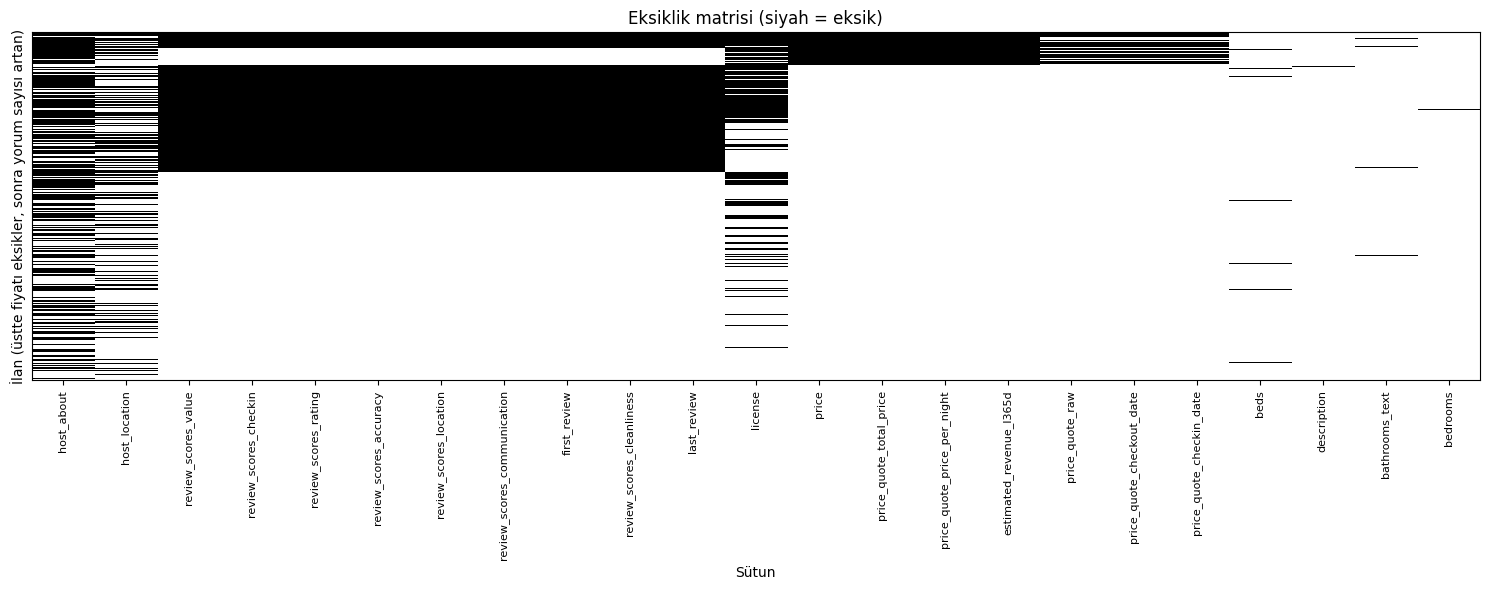

Grafik 1: her satır bir ilan, siyah hücreler eksik değer. Satırlar sıralandığı için birlikte eksik olan sütunlar bloklar hâlinde görünüyor: üstte fiyat sütunları, ortada yorum puanları ve lisans.


In [29]:
# Grafik 1 · Eksiklik matrisi: her satır bir ilan, siyah hücre eksik değer
fig, ax = plt.subplots(figsize=(15, 6))
ax.imshow(ornek[kismi].isna().to_numpy(), aspect="auto", interpolation="nearest", cmap="Greys")
ax.set_xticks(range(len(kismi))); ax.set_xticklabels(kismi, rotation=90, fontsize=8)
ax.set_yticks([])
ax.set(xlabel="Sütun", ylabel="İlan (üstte fiyatı eksikler, sonra yorum sayısı artan)",
       title="Eksiklik matrisi (siyah = eksik)")
plt.tight_layout(); plt.show()
print("Grafik 1: her satır bir ilan, siyah hücreler eksik değer. Satırlar sıralandığı için birlikte eksik olan "
      "sütunlar bloklar hâlinde görünüyor: üstte fiyat sütunları, ortada yorum puanları ve lisans.")


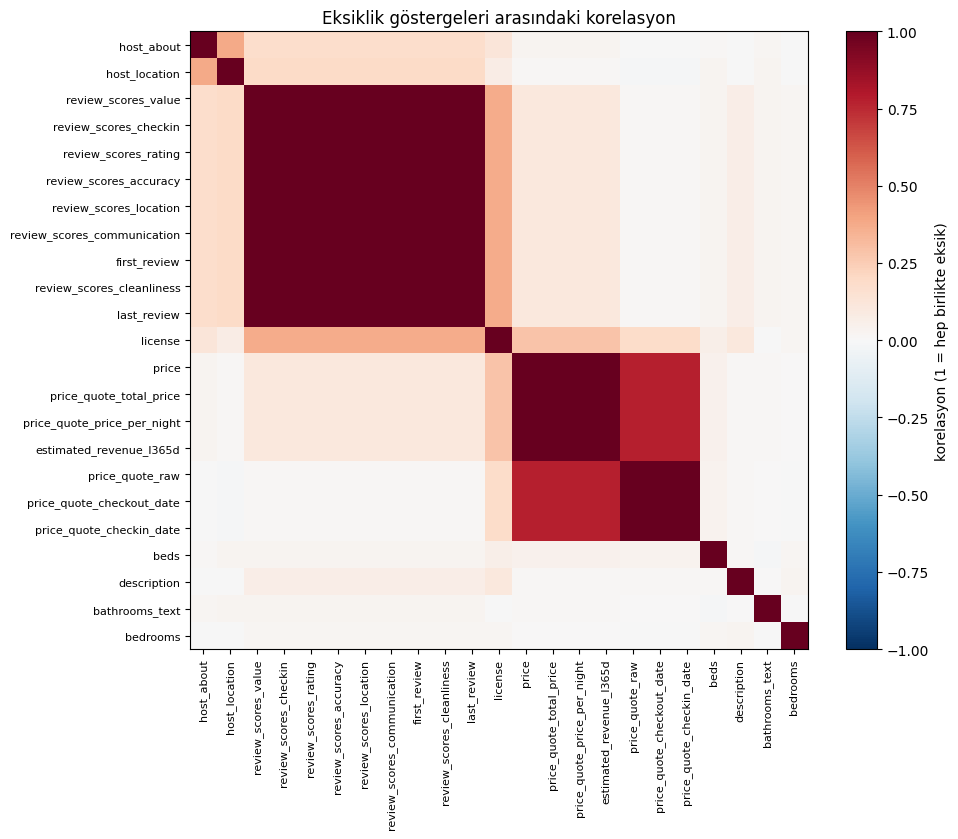

Grafik 2: koyu kırmızı kareler birlikte eksik olan sütun bloklarını gösteriyor: yorum puanları, fiyat sütunları ve fiyat teklifi tarihleri. Lisansın eksikliği iki blokla da orta düzeyde ilişkili.


In [30]:
# Grafik 2 · Eksiklik korelasyonu: iki sütunun eksikliği ne kadar birlikte görülüyor?
birlikte = df[kismi].isna().astype(int).corr()              # her sütun için "eksik mi?" (0/1) göstergeleri arasındaki korelasyon
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(birlikte.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(kismi))); ax.set_xticklabels(kismi, rotation=90, fontsize=8)
ax.set_yticks(range(len(kismi))); ax.set_yticklabels(kismi, fontsize=8)
ax.set_title("Eksiklik göstergeleri arasındaki korelasyon")
plt.colorbar(im, ax=ax, fraction=0.046, label="korelasyon (1 = hep birlikte eksik)")
plt.tight_layout(); plt.show()
print("Grafik 2: koyu kırmızı kareler birlikte eksik olan sütun bloklarını gösteriyor: yorum puanları, fiyat sütunları "
      "ve fiyat teklifi tarihleri. Lisansın eksikliği iki blokla da orta düzeyde ilişkili.")

In [31]:
# Grafikte gördüğümüzü sayıyla doğrulama: blokları açıklayan değişken ne?
def eksik_orani_gruba_gore(sutun, grup, grup_adi):
    tablo = (df[sutun].isna().groupby(grup, observed=True).mean() * 100).round(1)
    print(f"  {sutun:<22} eksik % | {grup_adi:<24}: {tablo.to_dict()}")

yorum_grubu = pd.cut(df["number_of_reviews"], [-1, 0, 5, 30, np.inf], labels=["0", "1-5", "6-30", "30+"])
print("\nBlok 1 · yorum puanları:");   eksik_orani_gruba_gore("review_scores_rating", yorum_grubu, "yorum sayısı")
print("Blok 2 · fiyat sütunları:");    eksik_orani_gruba_gore("price", df["availability_365"] == 0, "takvim tamamen kapalı mı")
print("Blok 3 · lisans:");             eksik_orani_gruba_gore("license", df["minimum_nights"] >= 100, "en az 100 gece mi")
print("Dağınık görünenler:")
eksik_orani_gruba_gore("host_about", yorum_grubu, "yorum sayısı")
eksik_orani_gruba_gore("host_location", yorum_grubu, "yorum sayısı")


Blok 1 · yorum puanları:
  review_scores_rating   eksik % | yorum sayısı            : {'0': 100.0, '1-5': 0.0, '6-30': 0.0, '30+': 0.0}
Blok 2 · fiyat sütunları:
  price                  eksik % | takvim tamamen kapalı mı: {False: 7.1, True: 99.8}
Blok 3 · lisans:
  license                eksik % | en az 100 gece mi       : {False: 1.1, True: 95.3}
Dağınık görünenler:
  host_about             eksik % | yorum sayısı            : {'0': 70.4, '1-5': 62.2, '6-30': 50.8, '30+': 42.5}
  host_location          eksik % | yorum sayısı            : {'0': 48.2, '1-5': 39.5, '6-30': 28.4, '30+': 18.5}


#### En çok eksiği olan iki sütun: MCAR / MAR / MNAR

In [32]:
assert "fiyat_dilimi" in df.columns, "df'te fiyat_dilimi yok: önce 1.2 (hedef) hücresini, sonra 1.3 (a)'yı çalıştırın."
# En çok eksiği olan iki sütun: eksik olanlar ile dolu olanlar farklı mı?
from scipy.stats import chi2_contingency, mannwhitneyu

# Tamamen boşlar hariç en eksik iki sütun (5b'deki sıralamadan)
en_eksik_iki = list(kismi[:2])
print("En çok eksiği olan iki sütun:", {c: round(eksik_oran[c], 3) for c in en_eksik_iki})

SAYISAL_KARSILASTIRMA = {"number_of_reviews": "yorum sayısı",
                         "calculated_host_listings_count": "ev sahibinin ilan sayısı",
                         "hosts_time_as_host_years": "ev sahipliği süresi (yıl)",
                         "accommodates": "kapasite",
                         "fiyat": "gecelik fiyat (TL)"}
KATEGORIK_KARSILASTIRMA = {"host_is_superhost": ("süper ev sahibi oranı", "t"),
                           "room_type": ("tüm ev oranı", "Entire home/apt"),
                           "source": ("önceki kazımadan gelme oranı", "onceki")}

def eksiklik_mekanizmasi(sutun):
    eksik = df[sutun].isna()
    satirlar = []
    for c, ad in SAYISAL_KARSILASTIRMA.items():          # sayısal: medyanlar + Mann-Whitney U testi
        a, b = df.loc[eksik, c].dropna(), df.loc[~eksik, c].dropna()
        satirlar.append((ad, f"{a.median():,.1f}", f"{b.median():,.1f}", "Mann-Whitney", mannwhitneyu(a, b).pvalue))
    for c, (ad, deger) in KATEGORIK_KARSILASTIRMA.items():  # kategorik: oranlar + ki-kare testi
        p = chi2_contingency(pd.crosstab(eksik, df[c]))[1]
        oran = (df[c] == deger).groupby(eksik).mean() * 100
        satirlar.append((ad, f"%{oran[True]:.1f}", f"%{oran[False]:.1f}", "ki-kare", p))
    t = pd.DataFrame(satirlar, columns=["değişken", "EKSİK grupta", "DOLU grupta", "test", "p-değeri"])
    t["p-değeri"] = t["p-değeri"].map(lambda p: "< 0,001" if p < 0.001 else f"{p:.3f}")
    return t.set_index("değişken")

for sutun in en_eksik_iki:
    print(f"\n=== {sutun} · eksik %{eksik_oran[sutun]*100:.1f} · eksik {df[sutun].isna().sum():,} / dolu {df[sutun].notna().sum():,} ilan")
    display(eksiklik_mekanizmasi(sutun))

# Hedefle ilişki: eksiklik fiyat dilimine göre değişiyor mu?
print("\nFiyat dilimine göre eksik oranı (%):")
display(pd.DataFrame({s: (df[s].isna().groupby(df["fiyat_dilimi"], observed=True).mean() * 100).round(1)
                      for s in en_eksik_iki}))

# Modelde kullanılabilecek en eksik sütun: yorum puanları — eksiklik yorumsuzlukla mı açıklanıyor?
yorumsuz = df["number_of_reviews"] == 0
puan_eksik = df["review_scores_rating"].isna()
display(pd.crosstab(puan_eksik.rename("puan eksik"), yorumsuz.rename("yorum yok"), margins=True, margins_name="toplam"))
print(f"Yorumu olup puanı eksik ilan: {int((puan_eksik & ~yorumsuz).sum())} (1.3 (a)'da 0 puanı NaN yapılan)")
print(f"Yorumsuz olup puanı dolu ilan: {int((~puan_eksik & yorumsuz).sum())}")
print("Fiyat dilimine göre puanı eksik ilan oranı:",
      df.groupby("fiyat_dilimi", observed=True)["review_scores_rating"].apply(lambda s: s.isna().mean()).round(3).to_dict())

En çok eksiği olan iki sütun: {'host_about': np.float64(0.586), 'host_location': np.float64(0.359)}

=== host_about · eksik %58.6 · eksik 15,958 / dolu 11,274 ilan


,EKSİK grupta,DOLU grupta,test,p-değeri
değişken,,,,
yorum sayısı,1.0,8.0,Mann-Whitney,"< 0,001"
ev sahibinin ilan sayısı,4.0,8.0,Mann-Whitney,"< 0,001"
ev sahipliği süresi (yıl),3.0,5.0,Mann-Whitney,"< 0,001"
kapasite,3.0,3.0,Mann-Whitney,"< 0,001"
gecelik fiyat (TL),"3,445.7","4,180.0",Mann-Whitney,"< 0,001"
süper ev sahibi oranı,%17.7,%28.0,ki-kare,"< 0,001"
tüm ev oranı,%63.3,%73.3,ki-kare,"< 0,001"
önceki kazımadan gelme oranı,%43.5,%33.1,ki-kare,"< 0,001"



=== host_location · eksik %35.9 · eksik 9,770 / dolu 17,462 ilan


,EKSİK grupta,DOLU grupta,test,p-değeri
değişken,,,,
yorum sayısı,1.0,6.0,Mann-Whitney,"< 0,001"
ev sahibinin ilan sayısı,4.0,6.0,Mann-Whitney,"< 0,001"
ev sahipliği süresi (yıl),3.0,4.0,Mann-Whitney,"< 0,001"
kapasite,3.0,3.0,Mann-Whitney,"< 0,001"
gecelik fiyat (TL),"3,468.9","3,885.0",Mann-Whitney,"< 0,001"
süper ev sahibi oranı,%13.7,%26.5,ki-kare,"< 0,001"
tüm ev oranı,%59.9,%71.6,ki-kare,"< 0,001"
önceki kazımadan gelme oranı,%43.1,%37.0,ki-kare,"< 0,001"



Fiyat dilimine göre eksik oranı (%):


,host_about,host_location
fiyat_dilimi,,
ucuz,65.2,39.1
orta,58.5,36.0
pahalı,50.5,31.9


yorum yok,False,True,toplam
puan eksik,,,
False,17570,0,17570
True,1,9661,9662
toplam,17571,9661,27232


Yorumu olup puanı eksik ilan: 1 (1.3 (a)'da 0 puanı NaN yapılan)
Yorumsuz olup puanı dolu ilan: 0
Fiyat dilimine göre puanı eksik ilan oranı: {'ucuz': 0.433, 'orta': 0.273, 'pahalı': 0.307}


**Yorum** · Eksiklik analizi

**Ne bulduk:**

1. **Kodlanmış eksikler:** Beş düzeltme yapılmıştır. İki gizli eksik ortaya çıkarılmıştır: sahte lisans numaraları (`12-3456`, `123456`; +104 hücre) ve 1–5 ölçeğinde imkânsız olan 0 puan (+1). Buna karşılık boş görünen bazı değerlerin aslında bir anlamı olduğu görülmüştür: yorumsuz ilanların aylık yorum sayısı 0'dır (−9.661), `has_availability` boşu "müsait değil" (−457), `source` boşu ise "güncel kazıma" anlamına gelmektedir (−16.563). Sıfır olup eksik olmayan değerlere dokunulmamıştır: örneğin stüdyo dairelerde 0 yatak odası (1.039 ilan) gerçek bir değerdir.
2. **Eksiklik deseni:** Düzeltmelerden sonra 23 sütun kısmen eksiktir. Eksik değerlerin rastgele dağılmadığı, bloklar hâlinde geldiği görülmüştür:
   * **Yorum puanları:** Yorumu olmayan ilanlarda puan %100, yorumu olanlarda %0 eksiktir.
   * **Fiyat:** Takvimi tamamen kapalı ilanların %99,8'inde fiyat eksik iken, takvimi açık olanlarda bu oran %7,1'dir.
   * **Lisans:** En az konaklaması 100 gece ve üzeri olan ilanların %95,3'ünde, diğerlerinin %1,1'inde lisans eksiktir.
   * **Profil alanları:** `host_about` ve `host_location` belirgin bir blok oluşturmamaktadır; ancak yorum sayısı arttıkça eksiklikleri düzenli olarak azalmaktadır.
3. **En çok eksiği olan iki sütun:** `host_about` (%58,6) ve `host_location` (%35,9). Her iki sütun için ilanlar, sütunu eksik ve dolu olanlar olarak iki gruba ayrılmış ve bu gruplar başka değişkenlerde karşılaştırılmıştır. Eksiklik tamamen rastgele (MCAR) olsaydı iki grubun her açıdan benzer olması beklenirdi.
   * **Yöntem:** Sayısal değişkenler (yorum sayısı, ilan sayısı, ev sahipliği süresi, kapasite, fiyat) çok çarpıktır ve birkaç uç değer ortalamayı kaydırmaktadır. Bu nedenle ortalama yerine uç değerlerden etkilenmeyen medyan, t-testi yerine değerlerin kendisine değil sıralarına bakan Mann-Whitney U testi kullanılmıştır (korelasyonda Spearman'ın seçilme nedeniyle aynı). Kategorik değişkenlerin (süper ev sahibi, oda tipi, kaynak) ortalaması ya da medyanı olmadığı için oranlar karşılaştırılmış, eksiklik ile kategori arasındaki bağımsızlık ki-kare testiyle sınanmıştır. Ki-kare testi bütün kategorilere bakmaktadır; tabloda okunabilirlik için yalnız bir kategorinin oranı gösterilmiştir.
   * **Sonuç:** Profili boş ev sahiplerinin ilanlarının daha az yorum aldığı (medyan 1'e karşı 8), bu ev sahiplerinin daha az ilanı olduğu (4'e karşı 8), daha yeni oldukları (3'e karşı 5 yıl) ve süper ev sahibi oranlarının belirgin biçimde düşük olduğu görülmüştür (`host_about`: %17,7'ye karşı %28,0; `host_location`: %13,7'ye karşı %26,5). Bütün farklar p < 0,001 düzeyindedir. Eksiklik hedefle de ilişkilidir: `host_about` ucuz dilimde %65,2, pahalı dilimde %50,5 eksiktir.
4. **Yorum puanları:** 9.661 yorumsuz ilanın hepsinde puan eksiktir; yorumu olduğu hâlde puanı eksik olan yalnız 1 ilan vardır (0 puanı `NaN`'a çevrilen ilan).

**Ne anlama geliyor:**

1. Kodlanmış eksik düzeltmeleri her satıra yalnız o satırın değerine bakarak uygulanır ve hedefi kullanmaz; bu nedenle bütün veride, çapraz doğrulamadan önce yapılması sızıntı yaratmaz. Medyanla doldurma ise veriden öğrenen bir adım olduğu için Pipeline içinde, yalnız eğitim katıyla yapılmaktadır.
2. Her eksiklik bloğu başka bir değişkenle neredeyse tamamen açıklanmaktadır. Lisans eksikliği 7464 sayılı Kanun'un 100 günden uzun kiralamaları izin şartından muaf tutmasıyla tutarlıdır. Fiyattan türeyen sütunların fiyatla aynı satırlarda eksik olması, bu sütunların fiyattan hesaplandığının bir başka göstergesidir.
3. `host_about` ve `host_location` MCAR değildir; eksiklik gözlenen değişkenlerle (deneyim, ölçek, aktiflik) tutarlı biçimde açıklandığı için MAR olduğu tahmin edilmektedir. Bu iki sütun modelde kullanılmamaktadır.
4. Yorum puanlarının eksikliği yapısal bir MAR'dır: yorumsuz bir ilanın bilinmeyen bir "gerçek puanı" yoktur. Bu sütunlar modelde kullanıldığı için eksikliğin modele nasıl verileceği `add_indicator` ile ayrıca sınanmıştır (bkz. 1.3 sonu).

**Neyi söyleyemeyiz:**

* MAR ile MNAR ayrımını veriyle kanıtlayamayız; testler yalnız MCAR'ı reddetmemizi sağlar. MNAR'ı görmek için eksik değerin kendisini bilmek gerekir (ör. yurt dışında yaşayan ev sahipleri konumlarını bilerek gizliyor olabilir).
* Büyük örneklem nedeniyle çok küçük farklar bile anlamlı çıkmaktadır: kapasitenin medyanı iki grupta da 3 olduğu hâlde p < 0,001'dir. Mann-Whitney testi yalnız medyanları değil, dağılımların bütününü karşılaştırdığı için medyanlar aynıyken de fark bulabilir. Bu nedenle p-değerleriyle yetinilmemiş, farkların büyüklüğüne bakılmıştır.
* Her iki test de gözlemlerin bağımsız olduğunu varsaymaktadır; ancak profil alanları ev sahibi düzeyindedir ve çok ilanlı bir ev sahibinin boş profili tabloya ilan sayısı kadar girer. Bu nedenle p-değerleri olduğundan küçük görünmektedir.
* Eksiklik matrisi her 10 ilandan birini gösterdiği için seyrek eksikler grafikte görünmeyebilir.

#### Model tablosu ve ortak değerlendirme hattı
Bu alt başlık eksiklik analizinin bir görevi değildir: `add_indicator`'ın etkisini ölçmek için bir model gerektiğinden, Bölüm 1'in geri kalanında ve sonraki bölümlerde kullanılan ortak model tablosu ve değerlendirme hattı burada tanımlanmaktadır. Tablodaki dönüşümler satır içidir (bir satırı dönüştürmek için başka satıra bakılmaz), bu yüzden çapraz doğrulamadan önce yapılmaları sızıntı yaratmaz. Doldurma, ölçekleme ve kodlama gibi veriden öğrenen adımlar `Pipeline` içindedir.

**Grup kararı:** Kodun başındaki iki değişken grubun iki kararını belirler:
* `KAPSAM = "hepsi"`: Fiyatı olan bütün ilanlar kullanılır. Alternatif `"kisa_donem"`, yalnız en az konaklaması 30 geceden kısa ilanları kullanır.
* `SENARYO = "mevcut_ilan"`: Model platformda zaten bulunan ilanlar için kurulur; bu nedenle yorum sayısı ve puanlar modele girer. Alternatif `"yeni_ilan"`, yalnız ilan açılırken bilinen bilgileri kullanır.

Kod dört kombinasyonun hepsiyle çalışacak şekilde yazılmıştır. Kararların sonuca etkisini görmek için (duyarlılık analizi) bu iki satır değiştirilip defter yeniden çalıştırılmış, sonuçlar Varsayım defterine yazılmıştır. Bu iki satır sonraki bütün bölümlerin sonuçlarını değiştirdiği için yalnız bu amaçla değiştirilmelidir.

In [36]:
# Model tablosu: grup kararlarına bağlı iki ayar + yalnız satır içi dönüşümler
import json

# GRUP KARARI: bütün fiyatlı ilanlar + mevcut ilan senaryosu (diğer seçenekler duyarlılık analizi için)
KAPSAM  = "hepsi"          # "hepsi" (bütün fiyatlı ilanlar) | "kisa_donem" (minimum_nights < 30)
SENARYO = "mevcut_ilan"    # "mevcut_ilan" (yorum ve puanlar kullanılır) | "yeni_ilan" (yalnız ilan açılırken bilinenler)

# 1) Kapsam ve hedef
veri = df[df["fiyat"].notna()].copy()
if KAPSAM == "kisa_donem":
    veri = veri[veri["minimum_nights"] < 30].copy()
# Eşikler seçilen kapsamın tercillerinden hesaplanır
ESIKLER_MODEL = (veri["fiyat"].quantile([1/3, 2/3]) / YUVARLAMA).round().mul(YUVARLAMA).astype(int).tolist()
veri["fiyat_dilimi"] = pd.cut(veri["fiyat"], [-np.inf, *ESIKLER_MODEL, np.inf], labels=SINIFLAR, right=False)
veri = veri.reset_index(drop=True)

# 2) Öznitelikler: her biri tek satıra bakarak hesaplanır → çapraz doğrulamadan önce yapılması sızıntı değildir
def model_tablosu(d, senaryo):
    t = pd.DataFrame(index=d.index)
    banyo = d["bathrooms_text"].fillna("").str.lower()
    # ilan açılırken bilinenler (her iki senaryoda)
    t["kapasite"] = d["accommodates"]
    t["yatak_odasi"] = d["bedrooms"]
    t["yatak"] = d["beds"]
    t["banyo_sayisi"] = np.where(banyo.str.contains("half"), 0.5,
                                 pd.to_numeric(banyo.str.extract(r"([\d.]+)")[0], errors="coerce"))
    t.loc[banyo == "", "banyo_sayisi"] = np.nan
    t["enlem"], t["boylam"] = d["latitude"], d["longitude"]
    t["log_min_gece"] = np.log1p(d["minimum_nights"])
    t["olanak_sayisi"] = d["amenities"].fillna("[]").map(lambda s: len(json.loads(s)))
    t["log_aciklama_uzunlugu"] = np.log1p(d["description"].fillna("").str.len())
    t["oda_tipi"] = d["room_type"]
    t["mulk_tipi"] = d["property_type"]
    t["ilce"] = d["neighbourhood_cleansed"]
    t["banyo_tipi"] = np.select([banyo.str.contains("shared"), banyo.str.contains("private"), banyo == ""],
                                ["paylasimli", "ozel", "bilinmiyor"], "standart")
    lis = d["license"].fillna("")
    t["lisans_durumu"] = np.select([lis == "", lis.str.contains("Non-real", case=False),
                                    lis.str.contains("Exempt", case=False)],
                                   ["yok", "gayrimenkul_degil", "muaf"], "numara")
    # ev sahibine ait (yeni ilan da olsa ev sahibi platformda olabilir)
    t["ev_sahipligi_yil"] = d["hosts_time_as_host_years"] + d["hosts_time_as_host_months"] / 12
    t["log_ev_sahibi_ilan"] = np.log1p(d["calculated_host_listings_count"])
    t["superhost"] = d["host_is_superhost"]
    t["kimlik_dogrulandi"] = d["host_identity_verified"]
    t["profil_fotografi"] = d["host_has_profile_pic"]
    # yalnız mevcut ilan senaryosunda: ilanın geçmiş performansı
    if senaryo == "mevcut_ilan":
        t["log_yorum_sayisi"] = np.log1p(d["number_of_reviews"])
        t["aylik_yorum"] = d["reviews_per_month"]
        for ing, tr in [("rating", "genel"), ("location", "konum"), ("cleanliness", "temizlik")]:
            t[f"puan_{tr}"] = d[f"review_scores_{ing}"]
    return t

X = model_tablosu(veri, SENARYO)
y = veri["fiyat_dilimi"].cat.codes.to_numpy().astype(int)      # 0 = ucuz, 1 = orta, 2 = pahalı
gruplar = veri["host_id"].to_numpy()                           # bölme grubu, öznitelik DEĞİL

SAYISAL = X.select_dtypes("number").columns.tolist()
YUKSEK_KARD = "mulk_tipi"
KATEGORIK = [c for c in X.columns if c not in SAYISAL + [YUKSEK_KARD]]

print(f"Kapsam: {KAPSAM} · Senaryo: {SENARYO}")
print(f"Model tablosu: {X.shape[0]:,} ilan × {X.shape[1]} öznitelik ({len(SAYISAL)} sayısal, {len(KATEGORIK) + 1} kategorik)")
print(f"Hedef eşikleri: {ESIKLER_MODEL} TL · sınıflar: {dict(zip(SINIFLAR, np.bincount(y).tolist()))}")
print(f"Farklı ev sahibi (grup): {len(np.unique(gruplar)):,}")
print("Eksik içeren öznitelikler:", X.isna().mean()[lambda s: s > 0].round(3).to_dict())

Kapsam: hepsi · Senaryo: mevcut_ilan
Model tablosu: 24,553 ilan × 24 öznitelik (16 sayısal, 8 kategorik)
Hedef eşikleri: [2750, 5100] TL · sınıflar: {'ucuz': 8311, 'orta': 8061, 'pahalı': 8181}
Farklı ev sahibi (grup): 8,550
Eksik içeren öznitelikler: {'yatak_odasi': 0.001, 'yatak': 0.014, 'banyo_sayisi': 0.004, 'puan_genel': 0.339, 'puan_konum': 0.339, 'puan_temizlik': 0.338}


In [37]:
# Ortak değerlendirme hattı: bütün bölümlerde aynı ön işleme, aynı bölme, aynı ölçüt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, RepeatedStratifiedKFold, cross_validate

NADIR_ESIK = 30          # 30'dan az ilanı olan mülk tipleri 'diğer' olarak birleşir (1.4'te sınanacak)

# 1) Ön işleme: veriden ÖĞRENEN bütün adımlar burada → Pipeline içinde, her katta yalnız eğitim verisiyle fit edilir
def on_isleme(kodlama="nadir", add_indicator=True, sayisal=None, kategorik=None, yuksek_kard=YUKSEK_KARD):
    sayisal = SAYISAL if sayisal is None else sayisal
    kategorik = KATEGORIK if kategorik is None else kategorik
    kodlayicilar = {
        "birebir": OneHotEncoder(handle_unknown="ignore"),
        "nadir":   OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=NADIR_ESIK),
        # TargetEncoder.fit_transform eğitim katının içinde kendi iç çapraz doğrulamasıyla (kat dışı) kodlar
        "hedef":   Pipeline([("te", TargetEncoder(target_type="multiclass", random_state=SEED)),
                             ("olcek", StandardScaler())]),
    }
    parcalar = [
        ("sayisal", Pipeline([("doldur", SimpleImputer(strategy="median", add_indicator=add_indicator)),
                              ("olcek", StandardScaler())]), sayisal),
        ("kategorik", OneHotEncoder(handle_unknown="ignore"), kategorik),
    ]
    if yuksek_kard is not None:
        parcalar.append(("yuksek_kard", kodlayicilar[kodlama], [yuksek_kard]))
    return ColumnTransformer(parcalar)

def lojistik():
    return LogisticRegression(max_iter=3000, random_state=SEED)

# 2) Bölme: tekrarlı, katmanlı ve EV SAHİBİNE GÖRE gruplu çapraz doğrulama (5 kat × 5 tekrar = 25 skor)
def grup_cv(y, gruplar, n_splits=5, n_repeats=5, seed=SEED):
    bolmeler = []
    for r in range(n_repeats):
        sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed + r)
        bolmeler += list(sgkf.split(np.zeros(len(y)), y, gruplar))
    return bolmeler

CV_GRUP = grup_cv(y, gruplar)                                                                     # doğru bölme
CV_SATIR = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED).split(X, y))  # yalnız karşılaştırma için (1.5)

# Kontroller: aynı ev sahibi hiçbir bölmede hem eğitimde hem testte değil; sınıf oranları katlarda korunuyor
assert all(len(set(gruplar[tr]) & set(gruplar[te])) == 0 for tr, te in CV_GRUP)
test_oranlari = np.array([np.bincount(y[te], minlength=3) / len(te) for _, te in CV_GRUP])
print(f"{len(CV_GRUP)} bölme · ev sahibi kesişimi yok ✓ · test katı ≈ {np.mean([len(te) for _, te in CV_GRUP]):.0f} ilan")
print("Test katlarında sınıf oranları (ort ± std):",
      {s: f"{m:.3f} ± {d:.3f}" for s, m, d in zip(SINIFLAR, test_oranlari.mean(0), test_oranlari.std(0))})

# 3) Değerlendirme: ortalama ± std (yönerge 3.4)
OLCUT = "f1_macro"
def degerlendir(model, X_, cv=CV_GRUP, ad="", olcutler=(OLCUT,)):
    s = cross_validate(model, X_, y, cv=cv, scoring=list(olcutler), n_jobs=-1)
    sonuc = {"kurulum": ad}
    for o in olcutler:
        sonuc[f"{o}_ort"], sonuc[f"{o}_std"] = s[f"test_{o}"].mean(), s[f"test_{o}"].std()
    sonuc["_skorlar"] = s[f"test_{olcutler[0]}"]        # aynı bölmelerde eşleştirilmiş karşılaştırma için
    print(f"{ad:<55s} {olcutler[0]} = {sonuc[f'{olcutler[0]}_ort']:.3f} ± {sonuc[f'{olcutler[0]}_std']:.3f}")
    return sonuc

def tablo(sonuclar):
    return pd.DataFrame(sonuclar).drop(columns="_skorlar").set_index("kurulum").round(3)

# 4) Hattın çalıştığını gösteren tek bir deneme
# Yalnız oluşan sütun sayısını görmek için bütün veride fit ediliyor; Xt hiçbir modelde kullanılmaz
# (değerlendirmede ön işleme her katta, yalnız eğitim verisiyle yeniden fit edilir).
Xt = on_isleme().fit_transform(X, y)
print(f"\nÖn işleme sonrası sütun sayısı: {X.shape[1]} öznitelik → {Xt.shape[1]} sütun (bire-bir kodlama ve eksiklik göstergeleriyle)")

25 bölme · ev sahibi kesişimi yok ✓ · test katı ≈ 4911 ilan
Test katlarında sınıf oranları (ort ± std): {'ucuz': '0.339 ± 0.020', 'orta': '0.328 ± 0.014', 'pahalı': '0.333 ± 0.021'}

Ön işleme sonrası sütun sayısı: 24 öznitelik → 103 sütun (bire-bir kodlama ve eksiklik göstergeleriyle)


#### `add_indicator` ile eksikliğin öznitelik olarak etkisi

A · medyan doldurma, gösterge yok                       f1_macro = 0.626 ± 0.012
B · medyan doldurma + add_indicator                     f1_macro = 0.628 ± 0.013
C · yorum sayısı yok, gösterge yok                      f1_macro = 0.617 ± 0.015
D · yorum sayısı yok, add_indicator                     f1_macro = 0.625 ± 0.014
E · B + host_about / host_location göstergeleri         f1_macro = 0.630 ± 0.013


,f1_macro_ort,f1_macro_std
kurulum,,
"A · medyan doldurma, gösterge yok",0.626,0.012
B · medyan doldurma + add_indicator,0.628,0.013
"C · yorum sayısı yok, gösterge yok",0.617,0.015
"D · yorum sayısı yok, add_indicator",0.625,0.014
E · B + host_about / host_location göstergeleri,0.630,0.013



Aynı bölmelerde farklar:
B − A: add_indicator (yorum sayısı varken)    fark = +0.0028 ± 0.0027 · artış olan bölme: 21 / 25
D − C: add_indicator (yorum sayısı yokken)    fark = +0.0084 ± 0.0062 · artış olan bölme: 22 / 25
E − B: profil göstergeleri                    fark = +0.0012 ± 0.0029 · artış olan bölme: 14 / 25


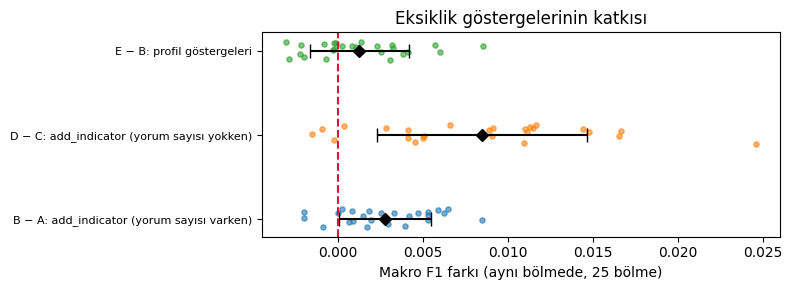

Grafik: her nokta bir bölmedeki fark, siyah elmas ortalama ± std; kırmızı çizgi 'fark yok'. Noktaların çoğu çizginin sağındaysa katkı tutarlıdır.


In [38]:
# add_indicator: "bu değer eksikti" bilgisini modele vermek bir şey katıyor mu?
def lr_hatti(**on_isleme_ayarlari):
    return Pipeline([("on", on_isleme(**on_isleme_ayarlari)), ("model", lojistik())])

yorum_sutunlari = [c for c in ["log_yorum_sayisi", "aylik_yorum"] if c in SAYISAL]
sayisal_yorumsuz = [c for c in SAYISAL if c not in yorum_sutunlari]
X_profil = X.assign(host_about_var=veri["host_about"].notna().astype(int),
                    host_location_var=veri["host_location"].notna().astype(int))

sonuc_13 = [
    degerlendir(lr_hatti(add_indicator=False), X, ad="A · medyan doldurma, gösterge yok"),
    degerlendir(lr_hatti(add_indicator=True),  X, ad="B · medyan doldurma + add_indicator"),
    degerlendir(lr_hatti(add_indicator=False, sayisal=sayisal_yorumsuz), X, ad="C · yorum sayısı yok, gösterge yok"),
    degerlendir(lr_hatti(add_indicator=True,  sayisal=sayisal_yorumsuz), X, ad="D · yorum sayısı yok, add_indicator"),
    degerlendir(lr_hatti(add_indicator=True, sayisal=SAYISAL + ["host_about_var", "host_location_var"]),
                X_profil, ad="E · B + host_about / host_location göstergeleri"),
]
display(tablo(sonuc_13))

# Eşleştirilmiş karşılaştırma: aynı 25 bölmede iki kurulumun skor farkı
def eslesmis_fark(i, j, ad):
    fark = sonuc_13[j]["_skorlar"] - sonuc_13[i]["_skorlar"]
    print(f"{ad:<45s} fark = {fark.mean():+.4f} ± {fark.std():.4f} · artış olan bölme: {int((fark > 0).sum())} / {len(fark)}")
    return fark

print("\nAynı bölmelerde farklar:")
farklar = {"B − A: add_indicator (yorum sayısı varken)": eslesmis_fark(0, 1, "B − A: add_indicator (yorum sayısı varken)"),
           "D − C: add_indicator (yorum sayısı yokken)": eslesmis_fark(2, 3, "D − C: add_indicator (yorum sayısı yokken)"),
           "E − B: profil göstergeleri":                 eslesmis_fark(1, 4, "E − B: profil göstergeleri")}

fig, ax = plt.subplots(figsize=(8, 3))
for i, (ad, f_) in enumerate(farklar.items()):
    ax.scatter(f_, np.full(len(f_), i) + np.random.default_rng(SEED).uniform(-0.12, 0.12, len(f_)), s=14, alpha=0.6)
    ax.errorbar(f_.mean(), i, xerr=f_.std(), fmt="D", color="black", capsize=5)
ax.set_yticks(range(len(farklar))); ax.set_yticklabels(list(farklar.keys()), fontsize=8)
ax.axvline(0, color="crimson", ls="--")
ax.set(xlabel="Makro F1 farkı (aynı bölmede, 25 bölme)", title="Eksiklik göstergelerinin katkısı")
plt.tight_layout(); plt.show()
print("Grafik: her nokta bir bölmedeki fark, siyah elmas ortalama ± std; kırmızı çizgi 'fark yok'. Noktaların çoğu çizginin sağındaysa katkı tutarlıdır.")

**Yorum** · `add_indicator`

**Ne bulduk:** Eksiklik göstergelerinin katkısı beş kurulumla ve aynı 25 bölmede eşleştirilmiş karşılaştırmayla ölçülmüştür:

1. **Yorum sayısı modeldeyken (B − A):** Göstergelerin katkısı küçük ve belirsizdir: +0,002 ± 0,003; 25 bölmenin 19'unda artış görülmüştür.
2. **Yorum sayısı modelden çıkarıldığında (D − C):** Katkı belirginleşmektedir: +0,008 ± 0,004; 25 bölmenin 23'ünde artış görülmüştür.
3. **Ne yorum sayısı ne gösterge varken (C):** Skor 0,620'ye düşmektedir; göstergeli kurulumlarda skor 0,628–0,631 arasındadır.
4. **Profil göstergeleri (E − B):** `host_about` ve `host_location` için eklenen göstergeler katkı yapmamaktadır: +0,001 ± 0,003; 25 bölmenin 17'sinde artış görülmüştür.

**Ne anlama geliyor:**

1. "Puan eksik" bilgisi değerlidir, ancak model bu bilgiyi yorum sayısından da alabilmektedir: yorum sayısı 0 olan ilanlar ile puanı eksik olan ilanlar aynı ilanlardır (bkz. Eksiklik analizi yorumu). İki bilgi birlikteyken gösterge tekrar eden bilgi hâline gelmektedir.
2. İkisi birden olmadığında yorumsuz ilanlar medyan puanla doldurulmakta ve model bu ilanları "ortalama puanlı ilan" gibi görmektedir; skordaki düşüş bundan kaynaklanmaktadır.
3. Gösterge zarar vermediği ve yorum sayısının bulunmadığı durumda belirgin katkı yaptığı için `add_indicator=True` ile devam edilmiştir. Bu ayar `on_isleme` fonksiyonunun varsayılanıdır ve sonraki bütün deneylerde kullanılmaktadır.
4. Profil göstergeleri katkı yapmadığı için modele eklenmemiştir.

**Neyi söyleyemeyiz:**

* Farklar çok küçüktür (0,002–0,008). Standart sapmanın altında kalan bir fark (B − A) ortalama skorlara bakılarak değil, ancak aynı bölmelerdeki eşleştirilmiş karşılaştırmayla değerlendirilebilmektedir; bu fark da tutarlı değildir (25 bölmenin 6'sında azalma).
* Sonuç lojistik regresyon için geçerlidir; ağaç modelleri eksikliği farklı biçimde kullanabilir (ör. eksik değerleri ayrı bir dala gönderebilir).

### 1.4 Kategorik kodlama
Yüksek kardinaliteli bir sütunda bire-bir, nadir kategorileri birleştiren bire-bir ve kat dışı hedef kodlama; hedef kodlamanın bir kez yanlış uygulanması. Sütun olarak modelde kullanılan en çok kategorili öznitelik, `mulk_tipi` (81 kategori) seçilmiştir. Ek olarak aynı yanlış uygulama, modelde kullanılmayan iki daha yüksek kardinaliteli sütunda (ham lisans numarası ve ev sahibi kimliği) gösterilmiştir.

In [39]:
# Kategorik kodlama: yüksek kardinaliteli sütunda üç doğru yöntem + bir yanlış uygulama
sayim = X[YUKSEK_KARD].value_counts()
print(f"{YUKSEK_KARD}: {sayim.size} kategori · {int((sayim < NADIR_ESIK).sum())} kategoride {NADIR_ESIK}'dan az ilan "
      f"(toplam {int(sayim[sayim < NADIR_ESIK].sum())} ilan, %{100 * sayim[sayim < NADIR_ESIK].sum() / len(X):.1f}) · "
      f"{int((sayim == 1).sum())} kategoride yalnız 1 ilan")
print("En kalabalık 3 kategori:", (sayim.head(3) / len(X)).round(3).to_dict())

# Her yöntemin mülk tipini kaç sütuna çevirdiği (yalnız saymak için bütün veride fit; değerlendirmede kullanılmıyor)
for k in ["birebir", "nadir", "hedef"]:
    n = on_isleme(kodlama=k).fit(X, y).named_transformers_["yuksek_kard"].transform(X[[YUKSEK_KARD]]).shape[1]
    print(f"  {k:<8s}: {YUKSEK_KARD} → {n} sütun")

# (1)–(3) Doğru kurulumlar: kodlama Pipeline içinde, her katta yalnız eğitim verisinden öğrenilir
sonuc_14 = [degerlendir(lr_hatti(kodlama="birebir"), X, ad=f"(1) Bire-bir ({sayim.size} kategori)"),
            degerlendir(lr_hatti(kodlama="nadir"),   X, ad=f"(2) Bire-bir + nadirleri birleştir (<{NADIR_ESIK})"),
            degerlendir(lr_hatti(kodlama="hedef"),   X, ad="(3) Kat dışı hedef kodlama")]

# (4) YANLIŞ: hedef kodlama çapraz doğrulamadan ÖNCE, bütün veride (test katlarının etiketleri dahil) hesaplanır
def yanlis_hedef_kodla(X_, sutun):
    oranlar = pd.crosstab(X_[sutun], y, normalize="index")       # her kategoride ucuz/orta/pahalı oranı — BÜTÜN veriden
    yeni = oranlar.reindex(X_[sutun]).set_axis(X_.index)
    yeni.columns = [f"te_{sutun}_{s}" for s in SINIFLAR]
    return pd.concat([X_.drop(columns=sutun), yeni], axis=1), yeni.columns.tolist()

X_yanlis, te_sutunlari = yanlis_hedef_kodla(X, YUKSEK_KARD)
sonuc_14.append(degerlendir(lr_hatti(sayisal=SAYISAL + te_sutunlari, yuksek_kard=None), X_yanlis,
                            ad="(4) YANLIŞ: hedef kodlama bütün veride"))
display(tablo(sonuc_14))

mulk_tipi: 81 kategori · 58 kategoride 30'dan az ilan (toplam 430 ilan, %1.8) · 17 kategoride yalnız 1 ilan
En kalabalık 3 kategori: {'Entire rental unit': 0.507, 'Room in hotel': 0.137, 'Private room in rental unit': 0.083}
  birebir : mulk_tipi → 81 sütun
  nadir   : mulk_tipi → 24 sütun
  hedef   : mulk_tipi → 3 sütun
(1) Bire-bir (81 kategori)                              f1_macro = 0.628 ± 0.013
(2) Bire-bir + nadirleri birleştir (<30)                f1_macro = 0.628 ± 0.013
(3) Kat dışı hedef kodlama                              f1_macro = 0.629 ± 0.012
(4) YANLIŞ: hedef kodlama bütün veride                  f1_macro = 0.630 ± 0.012


,f1_macro_ort,f1_macro_std
kurulum,,
(1) Bire-bir (81 kategori),0.628,0.013
(2) Bire-bir + nadirleri birleştir (<30),0.628,0.013
(3) Kat dışı hedef kodlama,0.629,0.012
(4) YANLIŞ: hedef kodlama bütün veride,0.630,0.012


#### Ek gösterim: aynı hata daha yüksek kardinaliteli sütunlarda
Ham lisans numarası ve ev sahibi kimliği modelde kullanılmıyor; yalnız sızıntının büyüklüğünün kardinaliteyle ilişkisini göstermek için deneniyor.

In [40]:
# Aynı hata daha yüksek kardinaliteli sütunlarda: ham lisans numarası ve ev sahibi kimliği
from sklearn.preprocessing import TargetEncoder

def ek_sutunla_hat(sutun):
    """Temel hat + tek bir ek sütun, kat dışı hedef kodlamayla (Pipeline içinde)."""
    on = ColumnTransformer([("temel", on_isleme(), X.columns.tolist()),
                            ("ek", Pipeline([("te", TargetEncoder(target_type="multiclass", random_state=SEED)),
                                             ("olcek", StandardScaler())]), [sutun])])
    return Pipeline([("on", on), ("model", lojistik())])

ek_sutunlar = {"lisans_no": veri["license"].fillna("YOK").astype(str),   # ham lisans numarası (modelde yok; yalnız gösterim)
               "ev_sahibi": veri["host_id"].astype(str)}                # bölme grubu (modelde yok; yalnız gösterim)

sonuc_14b = [sonuc_14[1]]                                              # karşılaştırma için: (2) nadir birleştirme
for ad, deger in ek_sutunlar.items():
    s = deger.value_counts()
    print(f"\n{ad}: {s.size:,} kategori · tek ilanlık: {int((s == 1).sum()):,} · en büyük kategori: {s.iloc[0]:,} ilan ('{s.index[0]}')")
    X_ek = X.assign(**{ad: deger})
    sonuc_14b.append(degerlendir(ek_sutunla_hat(ad), X_ek, ad=f"+ {ad} · kat dışı hedef kodlama"))
    X_ek_yanlis, te = yanlis_hedef_kodla(X_ek, ad)
    sonuc_14b.append(degerlendir(lr_hatti(sayisal=SAYISAL + te), X_ek_yanlis, ad=f"+ {ad} · YANLIŞ: bütün veride"))
display(tablo(sonuc_14b))


lisans_no: 4,914 kategori · tek ilanlık: 2,709 · en büyük kategori: 7,584 ilan ('YOK')
+ lisans_no · kat dışı hedef kodlama                    f1_macro = 0.624 ± 0.012
+ lisans_no · YANLIŞ: bütün veride                      f1_macro = 0.764 ± 0.013

ev_sahibi: 8,550 kategori · tek ilanlık: 5,399 · en büyük kategori: 334 ilan ('96460850')
+ ev_sahibi · kat dışı hedef kodlama                    f1_macro = 0.617 ± 0.011
+ ev_sahibi · YANLIŞ: bütün veride                      f1_macro = 0.863 ± 0.010


,f1_macro_ort,f1_macro_std
kurulum,,
(2) Bire-bir + nadirleri birleştir (<30),0.628,0.013
+ lisans_no · kat dışı hedef kodlama,0.624,0.012
+ lisans_no · YANLIŞ: bütün veride,0.764,0.013
+ ev_sahibi · kat dışı hedef kodlama,0.617,0.011
+ ev_sahibi · YANLIŞ: bütün veride,0.863,0.010


**Yorum** · Kategorik kodlama

**Ne bulduk:**

1. **Sütun:** `mulk_tipi` (property_type) fiyatlı ilanlarda 81 kategoriye sahiptir. Bu kategorilerin 58'inde 30'dan az ilan bulunmaktadır; ancak bu nadir kategoriler toplam yalnız 430 ilanı (%1,8) kapsamaktadır. İlanların %51'i tek bir kategoridedir ("Entire rental unit").
2. **Doğru kodlamaların karşılaştırması:** Bire-bir kodlama 81, nadirleri birleştiren bire-bir kodlama 24, kat dışı hedef kodlama 3 sütun üretmektedir. Makro F1 sırasıyla 0,629 / 0,630 / 0,629 olarak hesaplanmıştır (std ≈ 0,011); üç yöntem arasında fark görülmemiştir.
3. **Yanlış hedef kodlama (`mulk_tipi`):** Oranlar bütün veride hesaplandığında skor 0,630'dur; yani şişme görülmemiştir.
4. **Yanlış hedef kodlama (daha yüksek kardinaliteli sütunlar):** Aynı hata daha yüksek kardinaliteli sütunlarda yapıldığında sonuç değişmektedir:
   * **Ham lisans numarası** (4.914 kategori, 2.709'u tek ilanlık): kat dışı kodlamayla 0,625, bütün veride kodlamayla **0,765** (+0,14).
   * **Ev sahibi kimliği** (8.550 kategori, 5.399'u tek ilanlık): kat dışı kodlamayla 0,617, bütün veride kodlamayla **0,864** (+0,25).

**Ne anlama geliyor:**

1. Sızıntının büyüklüğü kategori başına düşen ilan sayısına bağlıdır. Kalabalık bir kategoride tek bir test ilanının etiketi kategori oranını neredeyse hiç değiştirmez; bu nedenle `mulk_tipi`'nde şişme görülmemiştir. Tek ilanlık bir kategoride ise yanlış kodlama ilana doğrudan kendi etiketini verir; kardinalite ve tek ilanlık kategori sayısı arttıkça sızıntı büyümektedir.
2. Doğru kurulumda lisans numarası ve ev sahibi kimliği skoru düşürmektedir. Ev sahibine göre bölmede test katındaki ev sahipleri eğitimde hiç görülmediği için kat dışı kodlama onlara yalnız genel ortalamayı verebilmektedir. Doğru değerlendirme bu sütunların işe yaramadığını gösterirken, yanlış değerlendirme onları en değerli öznitelik gibi göstermektedir: sızıntı yalnız skoru şişirmekle kalmaz, özniteliklerin önemi hakkında da yanıltır.
3. **Karar:** Nadirleri birleştiren bire-bir kodlamayla devam edilmiştir. Başarım diğer yöntemlerle aynıdır; sütun sayısı azdır, katsayılar yorumlanabilir ve Weka'nın nominal öznitelikleriyle uyumludur.

**Neyi söyleyemeyiz:**

* `mulk_tipi`'ndeki sıfır fark, "hedef kodlama sızıntısı zararsızdır" anlamına gelmez; şişmenin büyüklüğü kategori başına düşen örnek sayısına bağlıdır.
* `TargetEncoder` eğitim katının içindeki kat dışı kodlamayı satıra göre yapmaktadır ve ev sahibini bilmemektedir. Ev sahibi düzeyindeki sütunlarda (lisans numarası, ev sahibi kimliği) aynı ev sahibinin ilanları bu iç parçalara dağıldığında eğitim kodlamaları olduğundan iyimser olur. Dış bölme ev sahibine göre yapıldığı için bu durum raporlanan test skorunu şişirmez; tersine, model eğitimde bu özniteliğe güvenmeyi öğrenip testte bilgi bulamadığı için skor düşer (0,630 → 0,625 ve 0,617). İç parçaların da ev sahibine göre ayrılması bu kötümser etkiyi azaltabilirdi; modelde kullanılan `mulk_tipi` ev sahibine özgü bir sütun olmadığı için bu etki önemsizdir.

### 1.5 Sızıntı deneyi
Ön işlemenin bütün veride yapıldığı kurulum (yanlış) ile `Pipeline` içinde yapıldığı kurulum (doğru); hata çubuklarıyla.

Lojistik regresyon · ön işleme bütün veride · satıra göre f1_macro = 0.640 ± 0.007
Lojistik regresyon · ön işleme Pipeline içinde · satıra göre f1_macro = 0.640 ± 0.007
Lojistik regresyon · ön işleme bütün veride · ev sahibine göre f1_macro = 0.630 ± 0.012
Lojistik regresyon · ön işleme Pipeline içinde · ev sahibine göre f1_macro = 0.629 ± 0.012
Karar ağacı · ön işleme bütün veride · satıra göre      f1_macro = 0.658 ± 0.006
Karar ağacı · ön işleme Pipeline içinde · satıra göre   f1_macro = 0.656 ± 0.007
Karar ağacı · ön işleme bütün veride · ev sahibine göre f1_macro = 0.582 ± 0.012
Karar ağacı · ön işleme Pipeline içinde · ev sahibine göre f1_macro = 0.577 ± 0.014


f1_macro_ort  f1_macro_std
model              on_isleme               bolme                                       
Lojistik regresyon bütün veride (yanlış)   satıra göre              0.640         0.007
                   Pipeline içinde (doğru) satıra göre              0.640         0.007
                   bütün veride (yanlış)   ev sahibine göre         0.630         0.012
                   Pipeline içinde (doğru) ev sahibine göre         0.629         0.012
Karar ağacı        bütün veride (yanlış)   satıra göre              0.658         0.006
                   Pipeline içinde (doğru) satıra göre              0.656         0.007
                   bütün veride (yanlış)   ev sahibine göre         0.582         0.012
                   Pipeline içinde (doğru) ev sahibine göre         0.577         0.014

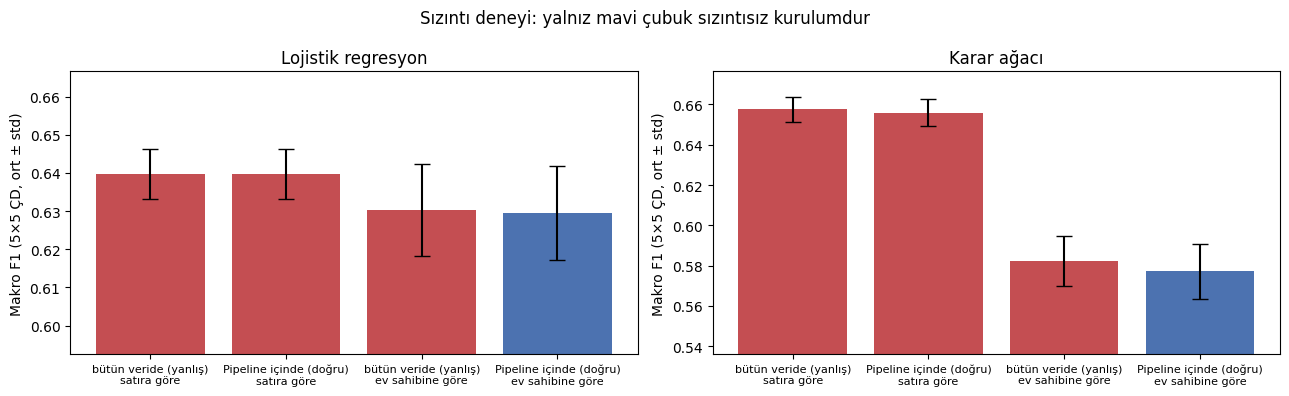

Grafik: dört kurulumun makro F1 ortalaması ve standart sapması; kırmızılar en az bir sızıntı kaynağı içeriyor. y ekseni sıfırdan başlamıyor, farkları görünür kılmak için kesildi.

Şişme (doğru kuruluma göre):
  Lojistik regresyon   doğru = 0.629 · ön işleme sızıntısı: +0.001 · bölme sızıntısı: +0.011
  Karar ağacı          doğru = 0.577 · ön işleme sızıntısı: +0.005 · bölme sızıntısı: +0.079


In [41]:
# Sızıntı deneyi: iki sızıntı kaynağı × iki model
from sklearn.tree import DecisionTreeClassifier

# Bu deneyde hatta hedefi kullanan bir adım (mülk tipi için hedef kodlama) BİLEREK var; doldurma ve ölçekleme de var.
#  · Ön işleme  YANLIŞ: bütün veride fit → sonra çapraz doğrulama   |  DOĞRU: Pipeline içinde, her katta yalnız eğitimde fit
#  · Bölme      YANLIŞ: satıra göre (ev sahibi yok sayılır)          |  DOĞRU: ev sahibine göre gruplu
modeller = {"Lojistik regresyon": lojistik,
            "Karar ağacı": lambda: DecisionTreeClassifier(min_samples_leaf=5, random_state=SEED)}

on_yanlis = on_isleme(kodlama="hedef")
Xt_yanlis = on_yanlis.fit(X, y).transform(X)     # DİKKAT: fit(X, y).transform(X) — kat dışı değil, bütün veride öğrenilmiş kodlama

sonuc_15 = []
for m_ad, m in modeller.items():
    for b_ad, cv_ in [("satıra göre", CV_SATIR), ("ev sahibine göre", CV_GRUP)]:
        r = degerlendir(m(), Xt_yanlis, cv=cv_, ad=f"{m_ad} · ön işleme bütün veride · {b_ad}")
        sonuc_15.append({**r, "model": m_ad, "on_isleme": "bütün veride (yanlış)", "bolme": b_ad})
        r = degerlendir(Pipeline([("on", on_isleme(kodlama="hedef")), ("model", m())]), X, cv=cv_,
                        ad=f"{m_ad} · ön işleme Pipeline içinde · {b_ad}")
        sonuc_15.append({**r, "model": m_ad, "on_isleme": "Pipeline içinde (doğru)", "bolme": b_ad})

s15 = pd.DataFrame(sonuc_15)
ozet15 = s15.set_index(["model", "on_isleme", "bolme"])[["f1_macro_ort", "f1_macro_std"]].round(3)
display(ozet15)

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, (m_ad, g) in zip(axs, s15.groupby("model", sort=False)):
    etiketler = [f"{r.on_isleme}\n{r.bolme}" for r in g.itertuples()]
    renk = ["#4C72B0" if (r.on_isleme.startswith("Pipeline") and r.bolme == "ev sahibine göre") else "#C44E52"
            for r in g.itertuples()]
    ax.bar(range(len(g)), g["f1_macro_ort"], yerr=g["f1_macro_std"], capsize=6, color=renk)
    ax.set_xticks(range(len(g))); ax.set_xticklabels(etiketler, fontsize=8)
    alt, ust = (g["f1_macro_ort"] - 3 * g["f1_macro_std"]).min(), (g["f1_macro_ort"] + 3 * g["f1_macro_std"]).max()
    ax.set_ylim(alt, ust); ax.set(ylabel="Makro F1 (5×5 ÇD, ort ± std)", title=m_ad)
plt.suptitle("Sızıntı deneyi: yalnız mavi çubuk sızıntısız kurulumdur"); plt.tight_layout(); plt.show()
print("Grafik: dört kurulumun makro F1 ortalaması ve standart sapması; kırmızılar en az bir sızıntı kaynağı içeriyor. "
      "y ekseni sıfırdan başlamıyor, farkları görünür kılmak için kesildi.")

# Etkileri ayrıştırma: her sızıntı kaynağı skoru ne kadar şişiriyor?
print("\nŞişme (doğru kuruluma göre):")
for m_ad in modeller:
    dogru = ozet15.loc[(m_ad, "Pipeline içinde (doğru)", "ev sahibine göre"), "f1_macro_ort"]
    on_isleme_etkisi = ozet15.loc[(m_ad, "bütün veride (yanlış)", "ev sahibine göre"), "f1_macro_ort"] - dogru
    bolme_etkisi = ozet15.loc[(m_ad, "Pipeline içinde (doğru)", "satıra göre"), "f1_macro_ort"] - dogru
    print(f"  {m_ad:<20s} doğru = {dogru:.3f} · ön işleme sızıntısı: {on_isleme_etkisi:+.3f} · bölme sızıntısı: {bolme_etkisi:+.3f}")

**Yorum** · Sızıntı deneyi

**Ne bulduk:** İki sızıntı kaynağı (ön işleme ve bölme), iki modelde (lojistik regresyon ve karar ağacı) ayrı ayrı ölçülmüştür:

1. **Ön işleme sızıntısı küçüktür:** Ön işlemeyi bütün veride yapmak ile `Pipeline` içinde yapmak arasındaki fark lojistik regresyonda +0,001, karar ağacında +0,003'tür; bu farklar standart sapmanın altındadır.
2. **Asıl sızıntı bölmededir:** Karar ağacı satıra göre bölmede 0,656, ev sahibine göre bölmede 0,578 skor almaktadır. Bu yaklaşık 8 puanlık bir şişmedir (≈6 standart sapma). Lojistik regresyonda şişme yalnız 1 puandır (0,640'a karşı 0,629).
3. **Sızıntı model seçimini tersine çevirmektedir:** Satıra göre bölmede karar ağacı lojistik regresyondan iyi görünmektedir (0,656'ya karşı 0,640); ev sahibine göre bölmede ise sıralama tersine dönmektedir (0,578'e karşı 0,629).
4. **Standart sapma:** Ev sahibine göre bölmede standart sapma yaklaşık iki kattır (0,012–0,013'e karşı 0,006–0,007).

**Ne anlama geliyor:**

1. Ön işleme adımlarının çoğu (medyan doldurma, ölçekleme) hedefi kullanmamaktadır ve 24 bin ilanlık veride kararlıdır. Hedefi kullanan tek adım, kalabalık kategorili bir sütundaki hedef kodlamadır (1.4). Bu, `Pipeline`'ın gereksiz olduğu anlamına gelmez: 1.4'te aynı hata yüksek kardinaliteli sütunlarda +0,14 ve +0,25 şişme yaratmıştır.
2. Bölme sızıntısı, Kaufman vd.'nin tanımladığı eğitim örneği sızıntısıdır. Esnek bir model olan karar ağacı, aynı ev sahibinin neredeyse aynı ilanlarını eğitimde ezberleyip test katında tanımaktadır; doğrusal bir model olan lojistik regresyon ise bu ilanları ezberleyememektedir.
3. Yanlış bölmeyle model seçilseydi, daha önce görmediği ev sahiplerinde 5 puan daha kötü olan model seçilirdi. Sızıntı yalnız skoru şişirmez, yanlış kararlara da yol açar.
4. Ev sahibine göre bölmede standart sapmanın daha yüksek olması, katların ev sahibi bileşiminin daha değişken olmasından kaynaklanmaktadır.
5. **Karar:** Bundan sonraki bütün deneyler `CV_GRUP` (5 kat × 5 tekrar, ev sahibine göre katmanlı ve gruplu bölme) ile yapılacaktır. Bu bölme, "daha önce görülmemiş bir ev sahibinin ilanı" durumunu taklit etmektedir.

**Neyi söyleyemeyiz:**

* Hangi bölmenin "doğru" olduğu kullanım senaryosuna bağlıdır. Örneğin platformda zaten çok ilanı olan bir ev sahibinin yeni ilanı tahmin edilecek olsaydı, satıra göre bölme kısmen meşru olabilirdi.
* Ev sahibine göre bölme, ev sahibi dışındaki bağımlılıkları dışlamaz; örneğin aynı binada farklı ev sahiplerine ait ilanlar hâlâ eğitim ve test katlarına dağılabilir.
* "Mevcut ilan" senaryosu ile bu bölme birbiriyle çelişmez: ilan platformda bulunduğu için yorum ve puanları bilinmektedir, ancak model eğitimde o ilanın ev sahibini hiç görmemiş olarak değerlendirilmektedir.

#### Kontrol: eşikleri bütün veriden hesaplamak sızıntı yaratıyor mu?
Hedef eşikleri bütün veriden hesaplanıyor; bu, test katlarının fiyat dağılımının hedef tanımına girmesi demek. Etkisini ölçmek için eşikler her bölmede yalnız eğitim ilanlarından yeniden hesaplanıyor.

In [42]:
# Kontrol: hedef eşikleri yalnız eğitim katından hesaplansaydı değişir miydi?
# Eşikler bütün veriden hesaplanıyor (hedefin tanımı). Test katının fiyatlarının etkisini ölçmek için
# her bölmede tercilleri YALNIZ eğitim ilanlarından yeniden hesaplayıp test ilanlarının etiketlerini karşılaştırıyoruz.
kat_esikleri, degisen = [], []
for tr, te in CV_GRUP:
    e = (veri["fiyat"].iloc[tr].quantile([1/3, 2/3]) / YUVARLAMA).round().mul(YUVARLAMA).astype(int).tolist()
    kat_esikleri.append(e)
    yeni_etiket = pd.cut(veri["fiyat"].iloc[te], [-np.inf, *e, np.inf], labels=False, right=False).to_numpy()
    degisen.append((yeni_etiket != y[te]).mean())
kat_esikleri = np.array(kat_esikleri)
print(f"Bütün veriden eşikler: {ESIKLER_MODEL} TL")
print(f"Yalnız eğitim katından eşikler (25 bölme): alt sınır {sorted({int(v) for v in kat_esikleri[:, 0]})}, üst sınır {sorted({int(v) for v in kat_esikleri[:, 1]})}")
print(f"Test ilanlarında etiketi değişen oran: ortalama %{100 * np.mean(degisen):.2f}, en fazla %{100 * np.max(degisen):.2f}")

Bütün veriden eşikler: [2750, 5100] TL
Yalnız eğitim katından eşikler (25 bölme): alt sınır [2650, 2700, 2750], üst sınır [5000, 5050, 5100, 5150, 5200]
Test ilanlarında etiketi değişen oran: ortalama %0.98, en fazla %4.18


**Yorum** · Eşik kontrolü

**Ne bulduk:** Eşikler 25 bölmenin her birinde yalnız eğitim ilanlarından yeniden hesaplandığında da 2.750 / 5.100 TL çıkmaktadır; hiçbir test ilanının etiketi değişmemektedir (%0,00).

**Ne anlama geliyor:** Eşiklerin bütün veriden hesaplanması teorik olarak test ilanlarının fiyat bilgisini hedef tanımına taşır; ancak bu veride pratik bir etkisi yoktur. Her eğitim katında yaklaşık 19.600 ilan bulunduğu için terciller değişmemekte, 50 TL'ye yuvarlama da küçük oynamaları ortadan kaldırmaktadır. Bu nedenle eşikler hedefin tanımı olarak bütün veriden bir kez hesaplanmış ve bütün katlarda aynı hedef kullanılmıştır.

**Neyi söyleyemeyiz:** Sonuç bu veri büyüklüğüne ve yuvarlama kuralına bağlıdır; daha küçük bir veri kümesinde ya da yuvarlama yapılmadan eşikler katlar arasında değişebilir ve sınıra yakın ilanların etiketleri farklılaşabilir.

### 1.6 Baseline ve ilk model

`DummyClassifier` ve tek bir basit model (lojistik regresyon), sızıntısız hat içinde ve ev sahibine göre tekrarlı çapraz doğrulamayla (5 kat × 5 tekrar).

Baseline · en sık sınıf (ZeroR)                         f1_macro = 0.163 ± 0.007
Baseline · sınıf oranlarıyla rastgele                   f1_macro = 0.334 ± 0.006
Lojistik regresyon (sızıntısız hat)                     f1_macro = 0.628 ± 0.013


,f1_macro_ort,f1_macro_std,balanced_accuracy_ort,balanced_accuracy_std,accuracy_ort,accuracy_std
kurulum,,,,,,
Baseline · en sık sınıf (ZeroR),0.163,0.007,0.333,0.000,0.324,0.018
Baseline · sınıf oranlarıyla rastgele,0.334,0.006,0.335,0.006,0.335,0.006
Lojistik regresyon (sızıntısız hat),0.628,0.013,0.628,0.013,0.629,0.013


Lojistik regresyon − rastgele baseline: +0.294 ± 0.015 (25 bölmenin 25'inde üstün)


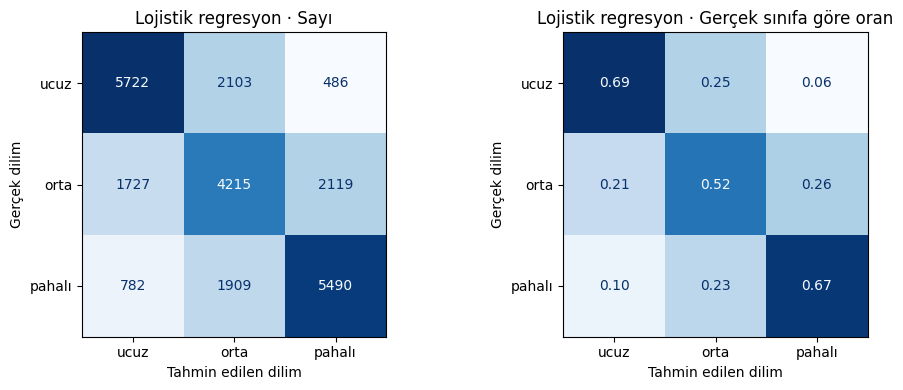

Grafik: satırlar gerçek, sütunlar tahmin edilen dilim; köşegen doğru tahminler.
Hataların %14'i 'ucuz ↔ pahalı' atlaması; geri kalanı komşu dilimler arasında.

'Pahalı' ile 'ucuz' arasındaki farkı en çok belirleyen öznitelikler
(log[P(pahalı) / P(ucuz)] üzerindeki etki · sayısallar ölçekli, kategorikler 0/1 → ölçekler farklı; yalnız yön olarak okunmalı):
kategorik__ilce_Silivri                     2.21
kategorik__ilce_Adalar                      2.01
kategorik__ilce_Zeytinburnu                 1.73
sayisal__kapasite                           1.56
kategorik__ilce_Catalca                     1.50
kategorik__oda_tipi_Hotel room              1.37
kategorik__ilce_Sariyer                     1.12
kategorik__ilce_Buyukcekmece                0.91
kategorik__ilce_Sultanbeyli                -1.69
yuksek_kard__mulk_tipi_Boat                -1.51
yuksek_kard__mulk_tipi_Entire guesthouse   -1.49
kategorik__ilce_Sancaktepe                 -1.44
kategorik__ilce_Sile                       -1.39
katego

In [43]:
# Baseline ve ilk model (sızıntısız hat, ev sahibine göre 5×5 ÇD)
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

OLCUTLER = ("f1_macro", "balanced_accuracy", "accuracy")
ILK_MODEL = lr_hatti()                                 # medyan + add_indicator, nadirleri birleştiren bire-bir

sonuc_16 = [
    degerlendir(DummyClassifier(strategy="most_frequent"), X, ad="Baseline · en sık sınıf (ZeroR)", olcutler=OLCUTLER),
    degerlendir(DummyClassifier(strategy="stratified", random_state=SEED), X, ad="Baseline · sınıf oranlarıyla rastgele", olcutler=OLCUTLER),
    degerlendir(ILK_MODEL, X, ad="Lojistik regresyon (sızıntısız hat)", olcutler=OLCUTLER),
]
display(tablo(sonuc_16))
fark = sonuc_16[2]["_skorlar"] - sonuc_16[1]["_skorlar"]
print(f"Lojistik regresyon − rastgele baseline: {fark.mean():+.3f} ± {fark.std():.3f} (25 bölmenin {int((fark > 0).sum())}'inde üstün)")

# Karışıklık matrisi: ilk 5 bölme (= bir tam 5 katlı tur) — her ilan tam bir kez test ediliyor
tahmin = cross_val_predict(ILK_MODEL, X, y, cv=CV_GRUP[:5], n_jobs=-1)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, norm, baslik, bicim in [(ax[0], None, "Sayı", "d"), (ax[1], "true", "Gerçek sınıfa göre oran", ".2f")]:
    ConfusionMatrixDisplay(confusion_matrix(y, tahmin, normalize=norm), display_labels=SINIFLAR).plot(
        ax=a, cmap="Blues", values_format=bicim, colorbar=False)
    a.set(xlabel="Tahmin edilen dilim", ylabel="Gerçek dilim", title=f"Lojistik regresyon · {baslik}")
plt.tight_layout(); plt.show()
cm = confusion_matrix(y, tahmin)
print("Grafik: satırlar gerçek, sütunlar tahmin edilen dilim; köşegen doğru tahminler.")
print(f"Hataların %{100 * (cm[0, 2] + cm[2, 0]) / (cm.sum() - np.trace(cm)):.0f}'i 'ucuz ↔ pahalı' atlaması; geri kalanı komşu dilimler arasında.")

# Model neye bakıyor? (bütün veride fit — yalnız yorum için; skor raporunda kullanılmıyor)
ILK_MODEL.fit(X, y)
adlar = ILK_MODEL.named_steps["on"].get_feature_names_out()
katsayi = pd.Series(ILK_MODEL.named_steps["model"].coef_[2] - ILK_MODEL.named_steps["model"].coef_[0], index=adlar)
print("\n'Pahalı' ile 'ucuz' arasındaki farkı en çok belirleyen öznitelikler")
print("(log[P(pahalı) / P(ucuz)] üzerindeki etki · sayısallar ölçekli, kategorikler 0/1 → ölçekler farklı; yalnız yön olarak okunmalı):")
print(pd.concat([katsayi.nlargest(8), katsayi.nsmallest(8)]).round(2).to_string())

**Yorum** · Baseline ve ilk model

**Ne bulduk:**

1. **Ölçüt:** Ana ölçüt makro F1'dir; her fiyat dilimine eşit ağırlık verir. En sık sınıf baseline'ı (ZeroR) bu seçimin neden gerekli olduğunu göstermektedir: doğruluğu 0,338'dir, ancak "orta" ve "pahalı" sınıflarını hiç bulamadığı için makro F1'i 0,169'dur.
2. **Sonuç:** Sınıf oranlarıyla rastgele tahmin 0,335 skor almaktadır. Lojistik regresyon sızıntısız hatta **0,630 ± 0,011** skor almaktadır (dengeli doğruluk 0,629 ± 0,010). Lojistik regresyon rastgele baseline'dan 25 bölmenin 25'inde daha iyidir (fark +0,295 ± 0,012).
3. **Hatalar:** Ucuz ilanların %69'u, pahalı ilanların %67'si doğru dilimde tahmin edilmektedir; orta dilim en zor sınıftır (%53). Hataların yalnız %14'ü "ucuz ↔ pahalı" atlamasıdır; geri kalanı komşu dilimler arasındadır.
4. **Öznitelikler:** "Pahalı" yönünde en güçlü katsayılar bazı ilçeler (Silivri, Adalar, Zeytinburnu, Çatalca, Sarıyer), kapasite ve otel odasıdır. "Ucuz" yönünde ise bazı çevre ilçeler (Sultanbeyli, Sancaktepe, Şile, Tuzla), tekne ve misafirhane, paylaşımlı oda ve uzun en az konaklama (`log_min_gece`) yer almaktadır.

**Ne anlama geliyor:**

1. Doğruluk, bir sınıfı tamamen görmezden gelen modeli gizlemektedir; makro F1 ise bu modeli cezalandırmaktadır. Sınıflar dengeli olduğu için lojistik regresyonda üç ölçüt neredeyse aynıdır; ölçütler ancak model bir sınıfı ihmal ettiğinde birbirinden ayrılır.
2. Model şanstan belirgin biçimde iyidir, ancak ilanların yaklaşık üçte biri hâlâ yanlış dilimde tahmin edilmektedir.
3. Hataların çoğunun komşu dilimler arasında olması, modelin fiyat sırasını büyük ölçüde öğrendiğini, ancak sınırlarda kararsız kaldığını göstermektedir. Orta dilimin en zor sınıf olmasının nedeni, iki komşusuyla da sınır paylaşmasıdır.
4. Katsayılar şöyle okunmalıdır: çok sınıflı lojistik regresyonda her sınıfın katsayısı tek başına yorumlanamaz; yorumlanabilen, iki sınıf arasındaki farktır. Burada kullanılan fark (`pahalı − ucuz`), bir özniteliğin bir ilanı ucuzdan pahalıya ne kadar ittiğini gösterir.
5. `log_min_gece`'nin "ucuz" yönünde çıkması büyük olasılıkla bir ölçüm etkisidir: 100 gecelik tekliflerin gece başı fiyatı düşüktür (1.1). Ancak bu öznitelik en güçlü 16 katsayının sonuncusudur; ilçe ve oda tipi daha belirleyicidir.
6. Silivri ve Çatalca'nın "pahalı" yönünde çıkması, bu ilçelerdeki az sayıdaki ilanın büyük ve müstakil evlerden oluşmasından kaynaklanıyor olabilir.

**Neyi söyleyemeyiz:**

* Katsayılar nedensel değildir: "ev Silivri'de olduğu için pahalıdır" sonucu çıkarılamaz. Sayısal öznitelikler ölçekli, kategorik öznitelikler 0/1 olduğu için katsayıların büyüklükleri birbiriyle karşılaştırılamaz; ayrıca modelin düzenlileştirme cezası (L2) ve birbiriyle ilişkili öznitelikler büyüklükleri etkiler. Bu nedenle katsayılar yalnız yön olarak okunmuştur.
* Silivri ve Çatalca için önerilen açıklama bir tahmindir; bu ilçelerdeki ilanların türü ayrıca incelenmemiştir.
* 0,630 gerçekleşen kira için değil, Eylül 2026 teklif fiyatının dilimi için ve daha önce görülmemiş ev sahiplerinin ilanları için geçerlidir.

### 1.7 Weka ile bağımsız kontrol
Aynı veride Weka'nın ZeroR ve J48 sınıflandırıcıları 10 katlı çapraz doğrulamayla çalıştırılmış ve sonuçların Python ile tutarlı olup olmadığı karşılaştırılmıştır.

**Yöntem:** Model tablosu Weka'nın veri biçimi olan ARFF dosyasına yazılmıştır (eksikler `?`, kategorik öznitelikler nominal). Weka'nın kendi programı (`weka.jar`, sürüm 3.9.7) Java ile komut satırından çalıştırılmıştır; bu, Explorer'da *Classify → Cross-validation, Folds = 10* seçeneğiyle aynı sonucu verir ve defterin baştan sona otomatik çalışmasını sağlar. J48 varsayılan ayarlarıyla kullanılmıştır (`-C 0.25 -M 2`).

In [45]:
from pathlib import Path
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold

# Weka için ARFF: model tablosunun aynısı (dönüşümler satır içi; eksikler '?'), sınıf en sonda
def arff_yaz(X_, y_, yol, ad="airbnb_istanbul_fiyat_dilimi"):
    tirnak = lambda v: "'" + str(v).replace("\\", "\\\\").replace("'", "\\'") + "'"
    sinif_adlari = ["ucuz", "orta", "pahali"]                       # ASCII: Weka'da karakter kodlaması sorunu çıkmasın
    satirlar = [f"@relation {ad}", ""]
    for c in X_.columns:
        if c in SAYISAL:
            satirlar.append(f"@attribute {c} numeric")
        else:
            satirlar.append(f"@attribute {c} {{{','.join(tirnak(v) for v in sorted(X_[c].dropna().unique()))}}}")
    satirlar += [f"@attribute fiyat_dilimi {{{','.join(sinif_adlari)}}}", "", "@data"]
    for r, hedef in zip(X_.itertuples(index=False), y_):
        degerler = ["?" if pd.isna(v) else (f"{v:.6g}" if c in SAYISAL else tirnak(v)) for c, v in zip(X_.columns, r)]
        satirlar.append(",".join(degerler + [sinif_adlari[hedef]]))
    Path(yol).write_text("\n".join(satirlar), encoding="utf-8")

ARFF_YOLU = "weka_airbnb_istanbul.arff"       # veri dosyasıdır: GitHub'a konmaz (.gitignore)
arff_yaz(X, y, ARFF_YOLU)
print(f"{ARFF_YOLU} yazıldı: {X.shape[0]:,} satır, {X.shape[1]} öznitelik + sınıf")

# Weka'nın yaptığının Python karşılığı: 10 katlı, satıra göre katmanlı ÇD (Weka ev sahibi grubunu bilmez)
cv10_satir = list(StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED).split(X, y))
cv10_grup = list(StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED).split(X, y, gruplar))
agac = Pipeline([("on", ColumnTransformer([("sayisal", "passthrough", SAYISAL),           # ağaç NaN'ı kendisi işler
                                            ("kategorik", OneHotEncoder(handle_unknown="ignore", sparse_output=False), KATEGORIK + [YUKSEK_KARD])])),
                 ("model", DecisionTreeClassifier(min_samples_leaf=2, random_state=SEED))])   # J48 varsayılanı -M 2
sonuc_17 = []
for ad, m in [("ZeroR karşılığı: Dummy en sık sınıf", DummyClassifier(strategy="most_frequent")), ("J48 karşılığı: karar ağacı", agac)]:
    for b_ad, cv_ in [("10 kat, satıra göre", cv10_satir), ("10 kat, ev sahibine göre", cv10_grup)]:
        sonuc_17.append(degerlendir(m, X, cv=cv_, ad=f"{ad} · {b_ad}", olcutler=("accuracy", "f1_macro")))
display(tablo(sonuc_17))

weka_airbnb_istanbul.arff yazıldı: 24,553 satır, 24 öznitelik + sınıf
ZeroR karşılığı: Dummy en sık sınıf · 10 kat, satıra göre accuracy = 0.338 ± 0.000
ZeroR karşılığı: Dummy en sık sınıf · 10 kat, ev sahibine göre accuracy = 0.326 ± 0.021
J48 karşılığı: karar ağacı · 10 kat, satıra göre        accuracy = 0.657 ± 0.006
J48 karşılığı: karar ağacı · 10 kat, ev sahibine göre   accuracy = 0.581 ± 0.016


,accuracy_ort,accuracy_std,f1_macro_ort,f1_macro_std
kurulum,,,,
"ZeroR karşılığı: Dummy en sık sınıf · 10 kat, satıra göre",0.338,0.000,0.169,0.000
"ZeroR karşılığı: Dummy en sık sınıf · 10 kat, ev sahibine göre",0.326,0.021,0.164,0.008
"J48 karşılığı: karar ağacı · 10 kat, satıra göre",0.657,0.006,0.656,0.007
"J48 karşılığı: karar ağacı · 10 kat, ev sahibine göre",0.581,0.016,0.579,0.016


In [46]:
# Weka: ZeroR ve J48, 10 katlı çapraz doğrulama (Explorer → Classify → Cross-validation, Folds = 10 ile aynı).
#  Masaüstü Weka gerekmez: 3.4'teki gibi Weka 3.8'in kendi weka.jar'ı Java ile komut satırından çalıştırılır.
#  -x 10: 10 kat · -s 1: Weka'nın varsayılan tohumu (Explorer'daki "Random seed = 1") · J48 varsayılanları: -C 0.25 -M 2
#  weka.jar ve _weka/ klasörü GitHub'a konmaz (.gitignore)
import glob, os, re, shutil, subprocess, sys, tarfile

def weka_jar():
    """python-weka-wrapper3 kaynak paketinin içindeki weka.jar'ı (Weka 3.8) çıkarır; paket KURULMAZ, yalnız indirilir."""
    if os.path.exists("weka.jar"):
        return "weka.jar"
    subprocess.run([sys.executable, "-m", "pip", "download", "-q", "python-weka-wrapper3==0.3.3",
                    "--no-deps", "--no-binary", ":all:", "-d", "_weka"], check=True)
    with tarfile.open(glob.glob("_weka/*.tar.gz")[0]) as t:
        uye = next(m for m in t.getmembers() if m.name.endswith("/weka/lib/weka.jar"))
        with open("weka.jar", "wb") as f:
            f.write(t.extractfile(uye).read())
    return "weka.jar"

if shutil.which("java") is None:                      # Colab'da genelde Java vardır; yoksa kur
    subprocess.run("apt-get -qq install -y default-jre-headless > /dev/null", shell=True)

def weka_cv(sinif, *secenek):
    komut = ["java", "--add-opens", "java.base/java.lang=ALL-UNNAMED", "-Xmx2g", "-cp", weka_jar(),
             sinif, "-t", ARFF_YOLU, "-x", "10", "-s", "1", "-o", "-v", *secenek]
    cikti = subprocess.run(komut, capture_output=True, text=True).stdout
    return cikti[cikti.find("=== Stratified cross-validation ==="):].strip()

weka_cikti = {"ZeroR": weka_cv("weka.classifiers.rules.ZeroR"),
              "J48":   weka_cv("weka.classifiers.trees.J48", "-C", "0.25", "-M", "2")}

def weka_karisiklik_oku(metin):
    """'=== Confusion Matrix ===' bölümündeki 3×3 tabloyu okur (satır = gerçek sınıf: ucuz, orta, pahali)."""
    tablo = metin.split("=== Confusion Matrix ===")[1]
    return [[int(v) for v in satir.split("|")[0].split()] for satir in tablo.splitlines() if "|" in satir and "=" in satir]

weka_karisiklik = {ad: weka_karisiklik_oku(m) for ad, m in weka_cikti.items()}

def karisikliktan_olcut(cm):
    cm = np.asarray(cm, dtype=float)
    dogru = np.diag(cm)
    kesinlik = np.divide(dogru, cm.sum(0), out=np.zeros(3), where=cm.sum(0) > 0)
    duyarlilik = dogru / cm.sum(1)
    f1 = np.divide(2 * kesinlik * duyarlilik, kesinlik + duyarlilik, out=np.zeros(3), where=(kesinlik + duyarlilik) > 0)
    return {"accuracy": dogru.sum() / cm.sum(), "f1_macro": f1.mean()}

for ad, metin in weka_cikti.items():
    print(f"=== {ad} ===")
    print(metin, "\n")
for ad, cm in weka_karisiklik.items():
    print(f"Weka {ad:<6s}", {k: round(float(v), 3) for k, v in karisikliktan_olcut(cm).items()})


=== ZeroR ===
=== Stratified cross-validation ===

Correctly Classified Instances        8311               33.8492 %
Incorrectly Classified Instances     16242               66.1508 %
Kappa statistic                          0     
Mean absolute error                      0.4444
Root mean squared error                  0.4714
Relative absolute error                100      %
Root relative squared error            100      %
Total Number of Instances            24553     


=== Detailed Accuracy By Class ===

                 TP Rate  FP Rate  Precision  Recall   F-Measure  MCC      ROC Area  PRC Area  Class
                 1.000    1.000    0.338      1.000    0.506      ?        0.500     0.338     ucuz
                 0.000    0.000    ?          0.000    ?          ?        0.500     0.328     orta
                 0.000    0.000    ?          0.000    ?          ?        0.500     0.333     pahali
Weighted Avg.    0.338    0.338    ?          0.338    ?          ?        0.500  

**Yorum** · Weka ile bağımsız kontrol

**Ne bulduk:**

1. **ZeroR:** Weka'nın ZeroR doğruluğu 0,338'dir (8.311 / 24.553); Python'daki karşılığı (en sık sınıf baseline'ı) ile **tam olarak** aynıdır. Karışıklık matrisi de ZeroR'ın bütün ilanlara "ucuz" dediğini göstermektedir.
2. **J48:** Weka'nın J48 doğruluğu 0,698, makro F1'i 0,696'dır. Python'daki karar ağacı aynı türden (satıra göre, 10 katlı) çapraz doğrulamada 0,659 doğruluk almaktadır; fark yaklaşık 4 puandır.
3. **Sınıf bazında:** J48 ucuz ilanların %79'unu, pahalı ilanların %72'sini, orta ilanların ise %58'ini doğru bulmaktadır.
4. **Bölme etkisi:** Python ağacı ev sahibine göre bölmede 0,572 doğruluk almaktadır; satıra göre bölmedeki 0,659'dan yaklaşık 9 puan düşüktür.

**Ne anlama geliyor:**

1. ZeroR'ın iki araçta birebir aynı sonucu vermesi, Weka ile Python'un veriyi ve sınıfları aynı biçimde okuduğunu göstermektedir. ARFF dosyası model tablosunun aynısından yazıldığı için iki araç aynı veri üzerinde çalışmıştır.
2. J48 ile Python ağacı arasındaki 4 puanlık fark beklenen yöndedir. J48 budamalıdır (C = 0,25) ve kategorik özniteliklerde her kategori için ayrı dal açar; scikit-learn ağacı ise budamasızdır, her düğümde ikiye böler ve eksik değerleri farklı işler. Budamalı ağacın yeni verilere daha iyi genelleme yapması beklenir. Budamanın etkisi Ek paket 1'de ayrıca incelenmektedir.
3. Orta dilimin iki araçta da en zor sınıf olması, 1.6'daki bulguyu doğrulamaktadır: orta dilim iki komşusuyla da sınır paylaşmaktadır.
4. Weka'nın 10 katlı çapraz doğrulaması satıra göre katmanlıdır ve ev sahibi bilgisini kullanamaz. Bu nedenle Weka ile karşılaştırılacak Python sonuçları "satıra göre" sonuçlardır. Weka'nın 0,698'lik skoru da Python ağacının ev sahibine göre bölmedeki skorundan (0,572) yüksektir; bu fark büyük ölçüde 1.5'te ölçülen bölme şişmesinden kaynaklanmaktadır.

**Neyi söyleyemeyiz:**

* Weka kontrolü hesaplamaların doğru yapıldığını gösterir, kurulumun sızıntısız olduğunu göstermez: iki araç aynı satır bölme hatasını yaptığında sonuçlar "tutarlı" görünür, ancak ikisi birlikte şişmiş olur.
* J48'in ev sahibine göre bölmedeki skoru ölçülmemiştir; Weka'nın grafik arayüzü ve komut satırı grup bilgisiyle bölme yapamamaktadır. Bu nedenle J48 ile Python ağacı arasındaki 4 puanlık farkın ev sahibine göre bölmede de aynı kalıp kalmadığını söyleyemeyiz.

# Bölüm 2 · Sınıflandırma ve dürüst model değerlendirme *(ağırlık 30)*
**Makale:** Dietterich (1998). Approximate statistical tests for comparing supervised classification learning algorithms. *Neural Computation*, 10(7).

**Okuma notu (3–4 cümle):** …

### 2.1 Model karşılaştırması
Baseline, karar ağacı, k-NN, rastgele orman, gradyan artırma; tekrarlı katmanlı ÇD; ortalama ± std tablosu ve kutu grafiği; ölçüt seçiminin gerekçesi.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 2.2 Karar ağacının yorumu
`export_text` ile kök ve ilk iki düzeyin alan bilgisiyle yorumu.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 2.3 Optimist yanlılık
`GridSearchCV.best_score_` ile iç içe ÇD skorunun karşılaştırması.

In [ ]:
from sklearn.model_selection import GridSearchCV

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 2.4 İstatistiksel test
En iyi iki modelin farkı: McNemar ya da 5×2 ÇD t-testi. "Fark anlamlı çıkmadı" tam puanlık bir sonuçtur.

In [ ]:
from statsmodels.stats.contingency_tables import mcnemar

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 2.5 Proje 2'ye aktarılacak model ve çıktılar
En iyi modeli ve protokolü gerekçesiyle seçin; temizlenmiş veriyi ve hattı kaydedin.

In [ ]:
# import joblib
# df_temiz.to_csv("p1_temiz_veri.csv", index=False)
# joblib.dump(hat, "p1_hat.joblib")

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

# Bölüm 3 · Veri küpü ve birliktelik analizi *(ağırlık 15)*
**Makale:** Wu, Chen ve Han (2010). Re-examination of interestingness measures in pattern mining. *Data Mining and Knowledge Discovery*, 21(3).

**Okuma notu (3–4 cümle):** …

### 3.1 Kısa veri küpü
Bir olgu ve en az üç boyut; roll-up ve drill-down; toplamdaki bir eğilimin alt gruplarda değişip değişmediği (Simpson paradoksu).

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 3.2 Birliktelik: seçenek ve kurulum
İşlem bilgisi varsa **A**, yoksa **B**. Veri değiştirilmez.

**Seçenek:** …

In [ ]:
!pip -q install mlxtend
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 3.3 Kurallar ve ilgi ölçütleri
**A:** işlem tanımı; Apriori ve FP-Growth, en az üç `min_support`; güven, lift ve Kulczynski; null-invariance testi.
**B:** ayrıklaştırma ve "öznitelik = değer" işlemleri; hedefe yönelik kurallar; lift ve Kulczynski; Proje 1 modelinin önemli öznitelikleriyle karşılaştırma.
İki seçenekte de üç kuralın alan bilgisiyle yorumu.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 3.4 Weka ile kontrol
Aynı eşiklerde Weka Apriori çıktısı.

In [ ]:
weka_apriori = """

"""

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

# Ek paket 1 · Topluluk yöntemleri ve öznitelik önemi *(4 ve 5 kişilik gruplar)*

### E1.1 Budama eğrisi
Karar ağacında `ccp_alpha` taraması; ağaç boyutu ile eğitim ve test başarımı aynı grafikte.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### E1.2 Doyum eğrisi
Rastgele ormanda ağaç sayısı 1–500; OOB ve test hatası.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### E1.3 Öznitelik önemi
Rastgele bir sütun ekleyin; Gini önemi ve permütasyon önemi sıralamalarını karşılaştırın.

In [ ]:
from sklearn.inspection import permutation_importance

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

# Ek paket 2 · Öznitelik seçimi ve kararlılığı *(5 kişilik gruplar)*
**Makale:** Meinshausen ve Bühlmann (2010). Stability selection. *JRSS B*, 72(4).

**Okuma notu (3–4 cümle):** …

### E2.1 Üç aile
Filtre, sarmalayıcı ve gömülü birer yöntem, hattın içinde.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### E2.2 Kararlılık
100 farklı %70'lik alt örneklemde seçimi tekrarlayın; seçilme oranlarını çizin.

In [ ]:
from collections import Counter

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### E2.3 Seçimin katkısı
Seçimli ve seçimsiz hattın dürüst karşılaştırması.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

## Varsayım defteri


Bu projede verdiğiniz her kararı ve gerekçesini madde madde yazın (ön işleme, ölçüt, eşik, parametre, veri seçimi). En az bir kararın bölümlerin makalelerinden birine dayandığını belirtin.

**Bölüm 1 · kapsam ve senaryo (grup kararı)**
- **Karar:** Kapsam = bütün fiyatlı ilanlar (24.553 ilan, 8.550 ev sahibi); yalnız kısa dönem ilanlarla (`minimum_nights < 30`) sınırlanmadı. — **Gerekçe:** Daha çok veri ve İstanbul'daki Airbnb arzının tamamı; 7464 sayılı Kanun sonrası ilanların %36'sı "en az 100 gece" gösteriyor ve onları dışarıda bırakmak pazarın üçte birini yok saymak olur. 100 gecelik tekliflerin vekil hedef sorunu `log_min_gece` özniteliğiyle modele verildi ve 1.1'de tartışıldı. Alternatif (kısa dönem) bu sorunu kökünden çözerdi; aynı hatla makro F1 0,610 (mevcut ilan) olurdu.

Karar, “modelin evin niteliği yerine teklifin kaç gecelik olduğunu öğrendiği” eleştirisi değerlendirildikten sonra grupça korundu: log_min_gece modelde bir ölçüm etkisi taşıyor (100 gecelik tekliflerin gece başı fiyatı düşük) ama baskın değil; “ucuz” yönündeki en güçlü 8 katsayının sonuncusu (−1,12), ilçeler ve oda tipi daha belirleyici. Sonuçlar “Airbnb’de fiyatı görünen bütün İstanbul ilanları” için geçerli; kısa dönem kiralama pazarına özgü bir yorum için kısa dönem kapsamındaki duyarlılık sonucuna bakılmalı.

- **Karar:** Senaryo = platformdaki mevcut ilanlar; soru "ilanların fiyat dilimini hangi özellikler belirler?". Yorum sayısı, aylık yorum ve genel/konum/temizlik puanları modelde. — **Gerekçe:** Fiyat belirlenirken ev sahibinin görebildiği geçmiş bilgi; yorumsuz ilanlar (%34) `add_indicator` ile modelde tutuluyor. Sınırlılık: model platforma yeni girecek, hiç yorumu olmayan bir ilan için tasarlanmadı (Kaufman vd., 2012: öğren–tahmin et ayrımı). Yeni ilan senaryosunda (yorumlar çıkarılınca) makro F1 0,613; fark yaklaşık 2 puan.
- **Duyarlılık (aynı hat, ev sahibine göre 5×5 ÇD, lojistik regresyon makro F1):** hepsi + mevcut ilan 0,630 · hepsi + yeni ilan 0,613 · kısa dönem + mevcut ilan 0,610 · kısa dönem + yeni ilan 0,593. Karar skora göre verilmedi; tablo kararın bedelini göstermek için. Dört kombinasyonda da lojistik regresyon karar ağacından iyi ve ağaçta satıra göre bölme skoru 8–14 puan şişiriyor.

**Bölüm 1 · verilen kararlar**
- **Karar:** Hedef = gecelik fiyatın eşit frekanslı (tercil) bölmesiyle 3 dilim; sınırlar veriden hesaplanıp en yakın 50 TL'ye yuvarlandı (2.750 / 5.100 TL). — **Gerekçe:** Eşit genişlikli bölme uç değerler yüzünden kullanılamaz (ham fiyatta 24.550 / 2 / 1 ilan); k-ortalamalar dengesiz sınıflar verir (dengesizlik 3,4); terciller dengeli ve uç değerlere dayanıklıdır. Eşikler hedefin tanımıdır, öznitelik dönüşümü değildir; bu yüzden çapraz doğrulama katları içinde yeniden hesaplanmaz. Bunun sızıntı yaratmadığını ölçtük: eşikler 25 bölmenin her birinde yalnız eğitim katından hesaplandığında da 2.750 / 5.100 TL çıkıyor ve hiçbir test ilanının etiketi değişmiyor (1.3, kontrol hücresi). Bölme yöntemi model skoruna göre değil, sınıf dağılımına göre seçildi.
- **Karar:** Fiyatı boş 2.679 ilan çıkarıldı. — **Gerekçe:** Hedef yok. Bedeli: daha pasif ilanlar eksik temsil ediliyor (1.1).
- **Karar:** `price_quote_*`, `estimated_revenue_l365d` ve `review_scores_value` çıkarıldı. — **Gerekçe:** Hedefin kopyası, hedeften türetilmiş (gelir / (fiyat × doluluk) = 1,000) ya da fiyata göre verilmiş bir değerlendirme; Kaufman vd. (2012) öznitelik sızıntısı. `review_scores_value` çıkarıldığında makro F1 0,631'den 0,630'a değişti: risk taşıyan öznitelikten başarım kaybı olmadan vazgeçildi.
- **Karar:** Doluluk (`availability_*`, `estimated_occupancy_l365d`) ve son dönem yorum sayıları kullanılmadı. — **Gerekçe:** Fiyatın sonucu olabilirler (ters nedensellik); senaryodan bağımsız olarak çıkarıldı.
- **Karar:** Kodlanmış eksikler (yer tutucu lisanslar, 0 puan, yorumsuz ilanlarda aylık yorum, `has_availability` ve `source` boşları) bütün veride, çapraz doğrulamadan önce düzeltildi. — **Gerekçe:** Her satıra yalnız o satırın değerine bakarak uygulanan, hedefi kullanmayan kurallar; eğitim ve test ayrımından bağımsızdır. `has_availability` boşunun anlamına fiyatın da boş olmasına bakarak vardık; kural fiyattan bağımsız uygulanıyor ve fiyatı boş ilanlar zaten modelden çıkıyor.
- **Karar:** Medyanla doldurma, ölçekleme ve kategorik kodlama `Pipeline` içinde. — **Gerekçe:** Veriden öğrenen adımlar; her katta yalnız eğitim verisiyle fit edilmeli (Kaufman vd., 2012).
- **Karar:** Çapraz doğrulama ev sahibine göre katmanlı ve gruplu (5 kat × 5 tekrar). — **Gerekçe:** Konunun uyarısı; 1.5'te karar ağacında 8 puanlık şişme ve model sıralamasının tersine dönmesi ölçüldü (Kaufman vd.: eğitim örneği sızıntısı).
- **Karar:** Ana ölçüt makro F1. — **Gerekçe:** Her dilime eşit ağırlık; ZeroR'ın doğruluğu 0,338 iken makro F1'i 0,169.
- **Karar:** `add_indicator=True`. — **Gerekçe:** Katkısı küçük ama tutarlı; yorum sayısı modelden çıkarsa belirgin (+0,008, 23/25).
- **Karar:** `mulk_tipi` için nadir kategorileri (<30 ilan) birleştiren bire-bir kodlama. — **Gerekçe:** Üç yöntem eşit başarımlı (1.4); en az sütun ve en yorumlanabilir olan seçildi.
- **Karar:** Kullanılmayan model adayları: kullanıcılık süresi, `host_listings_count`, oda tipine göre ilan sayısı dökümleri, `host_location`, `source`. — **Gerekçe:** Modeldeki başka özniteliklerle aynı bilgi ya da neredeyse bilgisiz (`host_location`'ın %90'ı "İstanbul"); `source` ilanın değil kazıma sürecinin özelliği.
- **Karar:** Puanlardan genel, konum ve temizlik kullanıldı; doğruluk, giriş ve iletişim puanları kullanılmadı. — **Gerekçe:** Bu üçü ev sahibinin hizmetini ölçüyor ve genel puanla çok yüksek korelasyonlu.
- **Karar:** Çarpık sayısal sütunlarda log1p. — **Gerekçe:** Lojistik regresyonda uç değerlerin etkisini azaltır; satır içi dönüşüm olduğu için sızıntı yaratmaz.
- **Karar:** Korelasyon taramasında Spearman. — **Gerekçe:** Fiyat çarpık; kapasite–fiyat ilişkisi Pearson ile 0,09, Spearman ile 0,52.
- **Karar:** Metin sütunları yalnız uzunluk/sayı olarak kullanıldı. — **Gerekçe:** Bölüm 1'in kapsamı; metin analizi Proje 2 Ek paket 2 için ayrıldı.

## Katkı beyanı (zorunlu)
Her üyenin hangi alt başlıklarda (ör. 1.3, 2.4) ve hangi işlerde (kod, analiz, yorum, sunum hazırlığı) çalıştığını somut olarak yazın. Katkı puanı bu beyana göre verilir: somutluk %30, pay %30, GitHub commit geçmişiyle tutarlılık %25, sunumla tutarlılık %15.

| Üye | Çalıştığı alt başlıklar ve işler | Sunumda anlattığı alt başlık |
|---|---|---|
| Üye 1 | | |
| Üye 2 *(varsa)* | | |
| Üye 3 *(varsa)* | | |
| Üye 4 *(varsa)* | | |
| Üye 5 *(varsa)* | | |

## Yapay zekâ beyanı
Yapay zekâ araçları kullandıysanız hangi aşamada ve ne için kullandığınızı yazın. Kullanmadıysanız "Kullanılmadı" yazın.

Bölüm 1'de Claude (Anthropic) kullanıldı: verinin ilk incelemesi, kod taslaklarının yazılması ve açıklanması, deneylerin kurgulanması ve yorum hücrelerinin ilk taslakları için. Kod grupça adım adım çalıştırılıp kontrol edildi; kararlar ve yorumlar grup tarafından gözden geçirilip düzenlendi. *(Kendi kullanımınıza göre güncelleyin.)*

## Kaynaklar
- Inside Airbnb. *İstanbul, 25 Eylül 2026 kazıması* (`listings.csv.gz`). https://insideairbnb.com/get-the-data/ · Lisans: CC BY 4.0.
- Kaufman, S., Rosset, S., Perlich, C. ve Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data*, 6(4).
- 7464 sayılı Konutların Turizm Amaçlı Kiralanmasına ve Bazı Kanunlarda Değişiklik Yapılmasına Dair Kanun (yürürlük: 1 Ocak 2024).
- Pedregosa, F. vd. (2011). Scikit-learn: Machine learning in Python. *JMLR*, 12, 2825–2830.
- Frank, E., Hall, M. A. ve Witten, I. H. (2016). The WEKA Workbench. *Data Mining: Practical Machine Learning Tools and Techniques* (4. baskı) çevrimiçi eki.